# 0DTE nearest-OTM straddle, every 30-min bar

> **2026-10-06: recalibration removed (user decision).** Every forecast
> is used as its plain back-transform $\widehat{RV}=\hat y^2B$ (§5); the
> session-bar Mincer–Zarnowitz map of the earlier runs is parked in
> `atm_straddle_lib` (`recal=True`). No interval is read: the library's
> block bootstrap is commented out (2026-10-03), so a printed interval
> equals its point estimate. Typed numbers in the markdown readings date
> from the recalibrated run unless a reading says otherwise; every
> printed output is the plain run's.

This notebook is **not** the paper 15:30→close trade
(`atm_straddle_rv_iv.ipynb`). It is one explicit choice of two
intraday extensions, spelled out before any table.

## Choice 1 — hold vs re-pick (instrument)

| | **Hold** (path of one straddle) | **Re-pick** (**this notebook**) |
|---|---|---|
| strikes | pick once, keep $K$ all day | new nearest-OTM at every 30-min bar $t$ |
| $R_t$ | 30-min mid path of **those** $K$; last bar cash-settles | next mid of the **$t$-straddle**; **15:30 cash-settles that straddle** |
| what it is | scalar expansion of one trade | a sequence of 30-min straddles |

**Proper $R_t$.** Pair the return with the forecast window.

- Re-pick + next-bar $\widehat{RV}_t$: $R_t =$ next mid of the straddle
  picked at $t$, divided by entry, minus 1 — a 30-min hold — for bars
  through 15:00. The **15:30** straddle cash-settles at the official
  close (the paper payoff): by decision, **no return in this trade uses
  a 16:00 quote**. The 16:00 stamp sits after the cash close — its
  quotes are carried-forward placeholders and its vendor implied
  volatility is entirely censored solver nodes (§3) — so the 16:00
  straddle is not built and the 15:30 exit is settlement, not the
  16:00 mid.

This notebook **re-picks**. It does not mark one straddle through the
day.

## No-peek protocol

Every position-forming quantity at bar $t$ is one of two things: the
bar's **own entry quote** (the tradable price at decision time), or
an estimate built **strictly from prior days, lagged at least one
day** — the time-of-day baseline $B$, the diurnal profile $w$,
the per-clock leverage medians. Realized exits enter only as
outcomes, never as inputs. No quantity differences two quotes taken
at different times: that construction (the implied-decay $\Delta V$)
embeds the later quote's view of the bar it brackets, and is
confined to parked studies. By construction a perturbation of
day-$d$ inputs cannot move a day-$d$ estimate; it registers on day
$d{+}1$.

The construction was re-audited after the bar-end alignment fix (the
forecast panel is bar-end labelled, so trade bar $t$ joins the row
stamped $t{+}30$ min): perturbing the joined row's realized variance,
whole days and single rows, leaves every same-day position unchanged.
The join-shift diagnostic for the close trade, which places the fresh
join on a smooth staleness curve and shows the jump one bar of actual
lookahead produces, lives in the RV–IV notebook and is not repeated
here. Upstream, `baseline` is a strictly-prior-days per-clock
estimator and every forecast feature carries the one-bar shift.

## Choice 2 — IV (same window as $\widehat{RV}$)

$\widehat{RV}_t$ is next-**30-min** realized variance (the plain
back-transform $\hat y^2B$ of the one-bar-ahead $y$; 2026-10-06). Implied variance has to live on that same window.

| pairing | implied variance | forecast | when it is right |
|---|---|---|---|
| 30-min pairing (retired; a units check in §5) | $\mathrm{IV}_{30}^{2}=(\mathrm{IV}^{\mathrm{hr}})^{2}/2$ | next-bar $\widehat{RV}_t$ | only at 15:30, where the remaining window is 30 min |
| remaining-session VRP | $(\mathrm{IV}^{\mathrm{hr}})^{2}\cdot h_t$ with $h_t$ hours left | **remaining** RV, not next-bar $\widehat{RV}$ | hold to close |
| **window-matched** (this notebook, §5b) | $(\mathrm{IV}^{\mathrm{hr}})^{2}\cdot h_t\cdot w_t$, $w_t$ the next bar's share | next-bar $\widehat{RV}_t$ | every clock: both sides on the same 30-min window |

At **15:30** the remaining window **is** 30 min, so the two pairings
coincide — that is the paper. At **10:00** they do not: remaining
session is ~6 hours; next-bar $\widehat{RV}$ is 30 min. Using
$\mathrm{IV}^{2}/2$ at 10:00 is the 30-min pairing, **not**
remaining-session VRP.

Hourly IV of the two legs is $(\mathrm{IV}_c+\mathrm{IV}_p)/2$ — equal-weight
on the two contracts, same as the close trade.

## Choice 3 — the open

The cash open is 9:30. The vendor file of 2026-09-18 replaces the old
9:30 clock — which carried no `underlying_price` at all and live mids on
only ~40% of days — with a **9:35** stamp that has a vendor spot and
live mids on all but two of the 1,279 sessions (§3 prints the count). So
the tape now offers a first straddle at 9:35.

That straddle is in the **quote-only** tables of this notebook (the
always-short return by clock in §4: a 25-minute hold to the 10:00 mid).
It is **not** in the forecast-scored trade (§5 onward): the forecast
lives on 30-minute bar-end stamps, and the 9:35 bar has no matching
row — a bar from 9:35 to 10:05 does not exist in the panel. The scored
trade therefore still starts at 10:00, now by construction of the
forecast grid rather than by a tape defect. `yfinance` is used only for
**settlement** (the official close of the 15:30 straddle).

In [1]:
import os
import sys
from pathlib import Path
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import yfinance as yf

sys.path.insert(0, str(Path.cwd() if (Path.cwd() / "atm_straddle_lib.py").exists() else Path.cwd() / "notebooks"))
import atm_straddle_lib as asl

REPO = asl.find_repo(Path.cwd())
OUT = REPO / "results" / "atm_straddle_intraday"
OUT.mkdir(parents=True, exist_ok=True)
CACHE = OUT / "cache"
CACHE.mkdir(parents=True, exist_ok=True)
print("repo:", REPO)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x: .6f}")


repo: C:\Users\james\CC Allowed\harxhar-0dte-professor


## 1. Load the 0DTE chain (every 30-min bar)

In [2]:
CHAIN_CODE_HASH = "078e03be01"
TRADE_CODE_HASH = "02f6fb20af"
# [cache:load]
import hashlib
import pyarrow.parquet as pq
path = REPO / "data" / "spxw_chain.parquet"
COLS = ["expiration", "timestamp", "strike", "cp", "bid", "ask", "mid",
        "underlying_price", "impl_volatility"]
opt = ["hours_to_expiration"]
_st = os.stat(path)
# Cache keys carry a hash of the construction cells' source (injected by
# the writer), so any change to the load/filter/pick/exit logic mints a
# new key and stale caches can never serve the new code. The trade key
# also carries the CONTENT hash of the settlement cache: every last bar
# settles against the official close, so a revised close changes those
# returns, and a key that named only the loader's source would go on
# serving the old ones.
_gspc_p = CACHE / "gspc_ohlc.parquet"


def _gspc_fp():
    if not _gspc_p.exists():
        return "nosettle"
    return hashlib.sha256(_gspc_p.read_bytes()).hexdigest()[:10]


def _trade_key():
    return CACHE / f"trade_{_st.st_size}_{_st.st_mtime_ns}_{TRADE_CODE_HASH}_{_gspc_fp()}.parquet"


_ck = CACHE / f"chain_0dte_{_st.st_size}_{_st.st_mtime_ns}_{CHAIN_CODE_HASH}.parquet"
_trade_ck = _trade_key()
print("settlement cache content hash in the trade key:", _gspc_fp())
if _trade_ck.exists():
    chain = None
    print("chain load skipped: trade cache hit (code-hashed key)")
elif _ck.exists():
    chain = pd.read_parquet(_ck)
    print("cache hit", _ck.name)
else:
    avail_cols = set(pq.ParquetFile(path).schema_arrow.names)
    keep_cols = [c for c in COLS + opt if c in avail_cols]
    raw = pd.read_parquet(path, columns=keep_cols)
    raw["timestamp"] = pd.to_datetime(raw["timestamp"], utc=True)
    raw["expiration"] = pd.to_datetime(raw["expiration"])
    raw["cp"] = raw["cp"].astype(str).str.upper().str[0]
    codes, uts = pd.factorize(raw["timestamp"])
    uet = pd.DatetimeIndex(uts).tz_convert("America/New_York")
    raw["et"] = uet.take(codes)
    raw["et_date"] = uet.normalize().take(codes)
    ecodes, uexp = pd.factorize(raw["expiration"])
    uexp_d = pd.DatetimeIndex(uexp).tz_localize("America/New_York", ambiguous="NaT", nonexistent="NaT").normalize()
    raw["exp_date"] = uexp_d.take(ecodes)
    raw["is_0dte"] = raw["et_date"] == raw["exp_date"]
    chain = raw[raw["is_0dte"]].copy()
    for old in CACHE.glob("chain_0dte_*.parquet"):
        old.unlink()
    chain.to_parquet(_ck)
if chain is not None:
    print("0DTE rows", f"{len(chain):,}")
    et0 = pd.to_datetime(chain["et"])
    print("clock times", sorted(et0.dt.strftime("%H:%M").unique()))
    print(chain.head(3))


settlement cache content hash in the trade key: 9d76153205
chain load skipped: trade cache hit (code-hashed key)


## 2. Regular hours; drop half-sessions

Twelve days in the file are half sessions: the cash market closed at
13:00 ET and the vendor carried the 13:00 quotes forward to a full
grid, so every stamp from 13:30 on is a frozen snapshot. A one-bar
hold between two frozen stamps records $R=0$ exactly — deflating the
pooled dispersion — and the last one settles against a close that was
already known at "entry". The chain says so itself:
`hours_to_expiration` is $\le 0$ at the 15:30 stamp on exactly those
days and on no other. That is the rule (`asl.early_close_days`),
shared with the close-trade notebook, and the dropped dates are
listed below. The days go whole; they are never re-pointed at the
13:00 bar, whose quotes are already the frozen snapshot while the
underlying print is older still.

In [3]:
# [cache:rth]
# The dropped dates are persisted beside the trade cache so this cell prints them
# whether or not the chain was reloaded: a cache hit must not hide the filter.
_ec_csv = CACHE / (_trade_ck.stem + "_early_close.csv")
if chain is None:
    print("filter applied when the cached trade was built; the dropped dates were persisted with it")
else:
    et = pd.to_datetime(chain["et"])
    mins = et.dt.hour * 60 + et.dt.minute
    rth = (mins >= 9 * 60 + 30) & (mins <= 16 * 60)
    chain = chain[rth].copy()
    if "hours_to_expiration" not in chain.columns:
        raise KeyError("chain has no hours_to_expiration: the half-session rule cannot be applied")
    # Shared rule (the deck applies the same one): hours_to_expiration <= 0 at the 15:30 stamp.
    chain, half = asl.drop_early_close(chain)
    pd.DataFrame({"date": [str(d.date()) for d in half]}).to_csv(_ec_csv, index=False)
    print("rows after RTH filter", f"{len(chain):,}", "days", chain["expiration"].nunique())
if _ec_csv.exists():
    _ec = pd.read_csv(_ec_csv)
    print("half-session days dropped (15:30 stamp already expired):", len(_ec))
    print("  ", ", ".join(_ec["date"].astype(str)))
else:
    print("no persisted half-session list beside this trade cache: delete it to rebuild")


filter applied when the cached trade was built; the dropped dates were persisted with it
half-session days dropped (15:30 stamp already expired): 12
   2020-11-27, 2020-12-24, 2021-11-26, 2022-11-25, 2023-07-03, 2023-11-24, 2024-07-03, 2024-11-29, 2024-12-24, 2025-07-03, 2025-11-28, 2025-12-24


## 2b. The first stamp is 9:35; the scored trade still starts at 10:00

The 2026-09-18 vendor file carries a **9:35** stamp with a vendor spot and
live mids on all but two of the 1,279 sessions (the old 9:30 clock had
neither), so a straddle can be picked at the open. It appears in the quote-only tables (§4, a
25-minute hold to the 10:00 mid). The forecast-scored trade (§5 onward)
starts at 10:00 because the forecast lives on 30-minute bar-end stamps
and no panel bar ends at 10:05. `yfinance` is used only for **settlement**
(the official close).

In [4]:
# [cache:gspc]
def load_gspc_ohlc(days):
    days = pd.to_datetime(days)
    cp = CACHE / "gspc_ohlc.parquet"
    if cp.exists():
        ohlc = pd.read_parquet(cp)
        ohlc.index = pd.to_datetime(ohlc.index)
        if ohlc.index.min() <= pd.Timestamp(days.min()) and ohlc.index.max() >= pd.Timestamp(days.max()):
            return ohlc
    raw = yf.download(
        "^GSPC",
        start=pd.Timestamp(days.min()) - pd.Timedelta("7D"),
        end=pd.Timestamp(days.max()) + pd.Timedelta("7D"),
        auto_adjust=True, progress=False, threads=True,
    )
    op, cl = raw["Open"].squeeze(), raw["Close"].squeeze()
    if isinstance(op, pd.DataFrame):
        op = op.iloc[:, 0]
    if isinstance(cl, pd.DataFrame):
        cl = cl.iloc[:, 0]
    out = pd.DataFrame({"open": op.to_numpy(float), "close": cl.to_numpy(float)}, index=op.index)
    ix = pd.to_datetime(out.index)
    if getattr(ix, "tz", None) is not None:
        ix = ix.tz_convert("America/New_York").tz_localize(None)
    out.index = ix.normalize()
    out.to_parquet(cp)
    return out.astype(float)

print("settlement source: GSPC official close via load_gspc_ohlc (cached)")


settlement source: GSPC official close via load_gspc_ohlc (cached)


## 3. Nearest-OTM straddle at each 30-min bar (re-pick; vendor $S$ only)

At every stamp, among quotes with a live midpoint: the call is the
smallest strike $K_c\ge S$, the put the largest $K_p\le S$. Two data
defects are guarded here rather than absorbed into a price
(`asl.pick_nearest_otm_guarded`).

- **No-quote sentinel.** `bid == ask == 0` is the vendor's "no
  quote", not a zero price; the midpoint is NaN and the contract is
  not live (`asl.quote_mid`). One-sided rows (`bid == 0`, `ask > 0`)
  keep their half-spread midpoint.
- **Vendor outages.** A stamp that lists a handful of contracts
  instead of a few hundred, or whose nearest OTM leg is more than
  10 points from the spot, is not a market. SPX strikes are 5 apart
  near the money, so one missing strike is tolerated and more than
  one is an outage. Those cells are dropped, with the reason, and
  listed below — the alternative is a "straddle" whose put is
  hundreds of points out of the money and whose return is a fiction.

In [5]:
# [cache:pick]
# Both the refused cells and the quote-hygiene counts are persisted beside the trade
# cache, so a cache hit still prints the evidence rather than hiding it.
_cells_csv = CACHE / (_trade_ck.stem + "_refused_cells.csv")
_diag_csv = CACHE / (_trade_ck.stem + "_pick_diag.csv")
if _trade_ck.exists():
    pkg = pd.read_parquet(_trade_ck)
    live = None
    print("trade cache hit", _trade_ck.name, "straddles", len(pkg), "days", pkg["expiration"].nunique())
    print(pkg[["expiration", "timestamp", "S", "K_c", "K_p", "entry"]].head())
else:
    live = chain.assign(mid=asl.quote_mid(chain["bid"], chain["ask"]).to_numpy())
    n_sentinel = int((live["mid"].isna() & np.isfinite(pd.to_numeric(chain["bid"], errors="coerce"))).sum())
    live = live[np.isfinite(live["mid"]) & (live["mid"] > 0)].copy()
    spot = asl.stamp_spot(live, ["expiration", "timestamp"])
    # A stamp with no live quote at all cannot even be offered to the guards: it forms no
    # straddle and simply leaves a hole in that day's grid. (The old file's 9:30 clock was
    # sparse by construction and was exempted here; the 2026-09-18 file's 9:35 stamp is
    # live on every session, so every dead stamp is now listed.)
    _dead = (pd.MultiIndex.from_frame(chain[["expiration", "timestamp"]].drop_duplicates())
             .difference(pd.MultiIndex.from_frame(live[["expiration", "timestamp"]].drop_duplicates())))
    _dead_et = pd.to_datetime(_dead.get_level_values(1), utc=True).tz_convert("America/New_York")
    _dead_rth = _dead_et
    pkg, dropped = asl.pick_nearest_otm_guarded(
        live[["expiration", "timestamp", "strike", "cp", "bid", "ask", "mid", "impl_volatility"]],
        spot, keys=("expiration", "timestamp"))
    _d = dropped.copy()
    _d["et"] = pd.to_datetime(_d["timestamp"], utc=True).dt.tz_convert("America/New_York")
    _d = pd.concat([_d, pd.DataFrame({"et": _dead_rth, "reason": "no_live_quote", "n_live": 0})],
                   ignore_index=True)
    _d.sort_values("et")[["et", "reason", "S", "K_c", "K_p", "gap", "n_live"]].to_csv(_cells_csv, index=False)
    pkg = asl.attach_iv_hourly_as_30min(pkg)
    n_iv_cens = int(pkg["iv_hourly"].isna().sum() - pkg[["impl_volatility_c", "impl_volatility_p"]].isna().any(axis=1).sum())
    pd.Series({
        "no-quote rows held out of the live frame (bid == ask == 0)": n_sentinel,
        "stamps with live quotes": int(live.groupby(["expiration", "timestamp"]).ngroups),
        "of which with a vendor spot": len(spot),
        "stamps with no live quote at all": len(_dead_et),
        "of them at the open (9:35)": int(((_dead_et.hour == 9) & (_dead_et.minute == 35)).sum()),
        "straddles with a censored vendor implied volatility": n_iv_cens,
    }, name="count").to_csv(_diag_csv)
    pkg = pkg.sort_values(["expiration", "timestamp"]).reset_index(drop=True)
    print("straddles", len(pkg), "days", pkg["expiration"].nunique())
    print(pkg[["expiration", "timestamp", "S", "K_c", "K_p", "entry"]].head())
if _diag_csv.exists() and _cells_csv.exists():
    print(pd.read_csv(_diag_csv, index_col=0)["count"].to_string())
    _cells = pd.read_csv(_cells_csv)
    print("cells refused by the outage guards or with no live quote:", len(_cells))
    print(_cells["reason"].value_counts().to_string())
    print(_cells.to_string(index=False))
else:
    print("no persisted pick diagnostics beside this trade cache: delete it to rebuild")


trade cache hit trade_80630573_1790200965970312800_02f6fb20af_9d76153205.parquet straddles 16619 days 1279
  expiration                 timestamp            S          K_c          K_p      entry
0 2020-01-03 2020-01-03 14:35:00+00:00  3235.780029  3240.000000  3235.000000  11.150000
1 2020-01-03 2020-01-03 15:00:00+00:00  3237.649902  3240.000000  3235.000000  10.750000
2 2020-01-03 2020-01-03 15:30:00+00:00  3237.679932  3240.000000  3235.000000   8.650000
3 2020-01-03 2020-01-03 16:00:00+00:00  3234.679932  3235.000000  3230.000000   8.900000
4 2020-01-03 2020-01-03 16:30:00+00:00  3236.000000  3240.000000  3235.000000   7.100000
no-quote rows held out of the live frame (bid == ask == 0)      449
stamps with live quotes                                       17903
of which with a vendor spot                                   17903
stamps with no live quote at all                                  3
of them at the open (9:35)                                        2
straddles with a ce

## 4. Exit: next-bar mid; the 15:30 bar cash-settles

Re-pick 30-min hold: $R_t = \mathrm{exit}_{t+1}/P_t - 1$ with
$\mathrm{exit}_{t+1}$ = next mid of **those** $K$, for bars
10:00–15:00; the 9:35 straddle is the same rule over a 25-minute hold
to the 10:00 mid (quote-only tables). If a leg is missing at $t+1$, the
row is dropped — counts printed below.

**15:30 / last bar** cash-settles vs `^GSPC` close — the paper
payoff on the 15:30 straddle.

In [6]:
# [cache:exit]
if "R" in pkg.columns and _trade_ck.exists():
    print("trade cache: skip exit rebuild")
    n_pkg = len(pkg)
else:
    et_pick = pd.to_datetime(pkg["timestamp"], utc=True).dt.tz_convert("America/New_York")
    is_1600 = (et_pick.dt.hour == 16) & (et_pick.dt.minute == 0)
    print("dropped", int(is_1600.sum()), "16:00 straddles (entry would be a 16:00 quote; excluded by decision)")
    pkg = pkg[~is_1600].copy()
    pkg["nxt_ts"] = pkg.groupby("expiration")["timestamp"].shift(-1)
    pkg["is_last"] = pkg["nxt_ts"].isna()
    days = pd.to_datetime(pkg["expiration"])
    if getattr(days.dt, "tz", None) is not None:
        days = days.dt.tz_convert("America/New_York").dt.tz_localize(None)
    days = days.dt.normalize()
    ohlc = load_gspc_ohlc(days)
    pkg["S_close"] = days.map(ohlc["close"])
    pkg["exit_settle"] = np.maximum(pkg["S_close"] - pkg["K_c"], 0.0) + np.maximum(pkg["K_p"] - pkg["S_close"], 0.0)
    nxt = pkg.loc[~pkg["is_last"], ["expiration", "nxt_ts", "K_c", "K_p"]].copy()
    left_c = nxt[["expiration", "nxt_ts", "K_c"]].rename(columns={"nxt_ts": "timestamp", "K_c": "strike"})
    left_p = nxt[["expiration", "nxt_ts", "K_p"]].rename(columns={"nxt_ts": "timestamp", "K_p": "strike"})
    quotes = live.loc[:, ["expiration", "timestamp", "strike", "cp", "bid", "ask", "mid"]]
    got_c = left_c.merge(quotes.loc[quotes["cp"] == "C", ["expiration", "timestamp", "strike", "bid", "ask", "mid"]],
                         on=["expiration", "timestamp", "strike"], how="left")
    got_p = left_p.merge(quotes.loc[quotes["cp"] == "P", ["expiration", "timestamp", "strike", "bid", "ask", "mid"]],
                         on=["expiration", "timestamp", "strike"], how="left")
    for _fld in ("mid", "bid", "ask"):   # next-bar quotes of the same strikes, persisted for the crossed-spread block
        nxt[f"{_fld}_c_nxt"] = got_c[_fld].to_numpy(dtype=float)
        nxt[f"{_fld}_p_nxt"] = got_p[_fld].to_numpy(dtype=float)
    pkg = pkg.merge(nxt[["expiration", "nxt_ts", "K_c", "K_p", "mid_c_nxt", "mid_p_nxt",
                         "bid_c_nxt", "bid_p_nxt", "ask_c_nxt", "ask_p_nxt"]],
                    on=["expiration", "nxt_ts", "K_c", "K_p"], how="left")
    pkg["exit_mark"] = pkg["mid_c_nxt"] + pkg["mid_p_nxt"]
    n_pkg = len(pkg)
n_last = int(pkg["is_last"].sum())
n_nonlast = n_pkg - n_last
miss_c = (~pkg["is_last"]) & pkg["mid_c_nxt"].isna()
miss_p = (~pkg["is_last"]) & pkg["mid_p_nxt"].isna()
miss_either = (~pkg["is_last"]) & ~np.isfinite(pkg["exit_mark"])
miss_settle = pkg["is_last"] & ~np.isfinite(pkg["exit_settle"])
bad_entry = ~np.isfinite(pkg["entry"]) | (pkg["entry"] <= 0)
print("straddles before exit filter", n_pkg)
print("last bar = 15:30 (cash-settle vs official close)", n_last)
print("non-last (next-mid path)", n_nonlast)
print("non-last missing next CALL mid", int(miss_c.sum()))
print("non-last missing next PUT mid", int(miss_p.sum()))
print("non-last missing either leg (row would drop)", int(miss_either.sum()),
      f"({100.0 * miss_either.sum() / max(n_nonlast, 1):.2f}% of non-last)")
print("last-bar missing GSPC settle", int(miss_settle.sum()))
print("bad entry (nonfinite or <=0)", int(bad_entry.sum()))

pkg["exit"] = np.where(pkg["is_last"], pkg["exit_settle"], pkg["exit_mark"])
keep = np.isfinite(pkg["entry"]) & np.isfinite(pkg["exit"]) & (pkg["entry"] > 0)
print("dropped at exit filter", int((~keep).sum()), "kept", int(keep.sum()))
pkg = pkg[keep].copy()
pkg["R"] = pkg["exit"] / pkg["entry"] - 1.0
pkg["R_as"] = -pkg["R"]
pkg["et"] = pd.to_datetime(pkg["timestamp"], utc=True).dt.tz_convert("America/New_York")
pkg["hour"] = pkg["et"].dt.hour
pkg["hhmm"] = pkg["et"].dt.strftime("%H:%M")
pkg["date"] = pkg["et"].dt.normalize().dt.tz_localize(None)
if not _trade_ck.exists():
    # The settlement cache is on disk now (this cell downloaded it if it was missing),
    # so re-mint the key with its content hash and carry the sidecars to the new stem.
    _stem0 = _trade_ck.stem
    _trade_ck = _trade_key()
    if _trade_ck.stem != _stem0:
        for _sc in CACHE.glob(_stem0 + "_*.csv"):
            _sc.rename(CACHE / _sc.name.replace(_stem0, _trade_ck.stem, 1))
        print("settlement cache was written during this run; trade key re-minted:", _trade_ck.name)
    for _old in CACHE.glob("trade_*"):       # stale caches and their diagnostic sidecars
        if not _old.name.startswith(_trade_ck.stem):
            _old.unlink()
    pkg.to_parquet(_trade_ck)
    print("wrote trade cache", _trade_ck.name)
print("bars with a return", len(pkg), "last-bar fraction", float(pkg["is_last"].mean()))
print("always-short R by clock time (no model; long R is the negative); 09:35 is a 25-minute hold to the 10:00 mid")
as_raw = pkg.groupby("hhmm")["R_as"].agg(["count", "mean", "std", "median"])
as_raw["t"] = as_raw["mean"] / as_raw["std"] * np.sqrt(as_raw["count"])
as_raw["Sharpe_ann"] = as_raw["mean"] / as_raw["std"] * np.sqrt(asl.PERIODS_PER_YEAR)
print(as_raw.to_string())


trade cache: skip exit rebuild
straddles before exit filter 16619
last bar = 15:30 (cash-settle vs official close) 1279
non-last (next-mid path) 15340
non-last missing next CALL mid 0
non-last missing next PUT mid 0
non-last missing either leg (row would drop) 0 (0.00% of non-last)
last-bar missing GSPC settle 0
bad entry (nonfinite or <=0) 0
dropped at exit filter 0 kept 16619


bars with a return 16619 last-bar fraction 0.07696010590288224
always-short R by clock time (no model; long R is the negative); 09:35 is a 25-minute hold to the 10:00 mid
       count      mean       std    median         t  Sharpe_ann
hhmm                                                            
09:35   1276  0.012950  0.112341  0.036585  4.117775    1.829943
10:00   1277  0.007205  0.151417  0.048701  1.700493    0.755405
10:30   1278  0.007297  0.148263  0.045593  1.759407    0.781270
11:00   1278  0.001557  0.135726  0.037640  0.410215    0.182157
11:30   1278  0.011395  0.121808  0.043083  3.344363    1.485074
12:00   1279  0.006863  0.123748  0.037344  1.983404    0.880392
12:30   1279  0.006968  0.125388  0.035644  1.987380    0.882157
13:00   1279  0.007116  0.196838  0.052469  1.292858    0.573873
13:30   1279  0.012318  0.174841  0.059880  2.519539    1.118372
14:00   1279  0.006572  0.252436  0.077369  0.931090    0.413292
14:30   1279  0.026143  0.294782  0.099071  3.171

## Side question: vendor IV units (Chris hourly)

The chain column is `impl_volatility` (exported as `new_implied_vol`).
OptionMetrics' **manual** says that field is an **annualized** Black–Scholes
vol: ATM SPX should be on the order of $0.20$ ($20\%$). A 30-minute
variance from that reading would be

$$
\sigma_{\mathrm{ann}}^{2}\times\frac{0.5}{252\times 6.5}
\sim 0.04\times 3\times 10^{-4}
\sim 10^{-5}\text{--}10^{-6}
$$

if the $0.20$ were real.

**What is in the file** is a couple of thousandths at ATM — the cell
below prints the median, $0.0025$ — not $0.20$: two orders of
magnitude too small to be annualized vol. A $0.25\%$ annualized vol
cannot price the $\sim\$13$ ATM straddle whose median the same cell
prints; those mids are $\sim 20\%$ vol.
That size mismatch is the unit tell.

Read the number as a **1-hour standard deviation** of returns (Chris:
"hourly vol") and the scale matches $\widehat{RV}$:

$$
\mathrm{Var}(1\mathrm{h})=0.0025^{2}=6.3\times 10^{-6},\qquad
\mathrm{Var}(30\mathrm{min})=\tfrac12\times 6.3\times 10^{-6}
=3.2\times 10^{-6},
$$

which are the `already_window` and `chris_hourly` medians the cell
prints. Median $\widehat{RV}$ here is $\sim 3.3\times 10^{-6}$: the
same size. Treat the vendor number as
OM-annualized and shrink by $1/(252\times 6.5)$ and you get
$\sim 10^{-9}$ (`annualized_om` below) — not comparable to
$\widehat{RV}$. We do not use that.

Hence $\mathrm{IV}_{30}=\mathrm{IV}^{\mathrm{hr}}/\sqrt{2}$ and
$\mathrm{iv\_var}=(\mathrm{IV}^{\mathrm{hr}})^{2}/2$. No inversion from
the mid. Other scripts in the repo ignore the vendor number and invert
BS with $\tau=h_{\mathrm{close}}/(252\times 6.5)$; that is a different
convention.

For the **30-min hold** pairing this notebook uses
$\mathrm{iv\_var}=(\mathrm{IV}^{\mathrm{hr}})^{2}\cdot 0.5$ at every
bar — the same window as next-bar $\widehat{RV}$. That is
remaining-session variance **only** at 15:30, where 30 minutes is what
is left.

In [7]:
iv = pkg["iv_hourly"].astype(float)
print("median vendor IV", float(iv.median()), "median straddle mid", float(pkg["entry"].median()))
conv = asl.iv_var_from_conventions(iv, hours_remaining=0.5)
for k, s in conv.items():
    print(k, "median var", float(s.median()))
print("30-min pairing: iv_var = (IV_hr)^2 * 0.5  [used]")
print("remaining-session pairing would need hours_left * (IV_hr)^2 and remaining RV [not used]")


median vendor IV 0.0025254557258449495 median straddle mid 14.049999952316284
chris_hourly median var 3.1889633127489603e-06
annualized_om median var 1.9468640492972895e-09
already_window median var 6.3779266254979206e-06
30-min pairing: iv_var = (IV_hr)^2 * 0.5  [used]
remaining-session pairing would need hours_left * (IV_hr)^2 and remaining RV [not used]


## 5. Forecasts (the same back-transform as the close trade)

2026-10-06: recalibration removed (user decision). The close trade and
this notebook share `load_yhat_panel`, which returns the plain
back-transform:

1. Forecasts live on $y=\sqrt{RV/B}$, $B$ the time-of-day baseline.
2. $\widehat{RV}_t=\widehat{y}_t^{\,2}B_t$ on every bar, with nothing
   estimated on top: no level map, no residual-variance term, no
   weighting. Squaring a forecast of $\sqrt{RV/B}$ tends to forecast
   $RV$ low (Jensen); the §5b cell prints the ratio of forecast to
   realized by year.
3. The regular-session mask (rows labelled 10:30–16:00 on dates with a
   stamp-16:00 row; the 2001–2025 NYSE 13:00 early-close dates out) is
   kept as the `in_fit` flag. The profile $w$ of §5b is built on those
   rows and the alignment check below uses it; it fits nothing in the
   forecast any more. The cell prints the flagged-row count and how
   many panel rows fall on early-close dates.

The close-trade notebook keeps the 15:30 row of the same forecast; this
notebook keeps every row.

$\widehat{RV}_t$ forecasts $RV$ for the **next 30-min bar**, not the
remaining session.

**Alignment.** Panel stamps are **bar-end labelled**: the row at
stamp $\tau$ carries the realized variance of $[\tau-30,\tau]$ and
the forecast of that same bar, issued at $\tau-30$ (the RV–IV
notebook measures the lead–lag peak correlation at one bar and the
same-row MZ slope near one). A trade entered at
$t$ therefore pairs with the **stamp $t{+}30$ row** — the forecast
issued at $t$ for the bar actually held — and that row's realized
variance is the bar's own. Earlier versions paired stamp $t$ with
trade $t$: causal (a *stale* forecast, the opposite of lookahead)
but one bar behind, and it shifted every per-clock realized
attribution by one row. The loader flags every regular-session row
(`in_fit`); the cell asserts that every joined trade bar is one of
them, which is the alignment check in one line.

**When there is no signal.** A bar keeps its return whenever the
forecast panel has a row for it. One thing can still leave it without
a *signal*: the vendor's implied volatility on either leg is a
censored solver node (§3). That is the only $q=0$ case — the diurnal
profile of §5b is seeded from the panel's own history and is warm
before the first scored day. Such bars sit flat in the rules that use
the forecast and are unaffected in the rules that do not, so every
rule in §6 is scored on the same bars. Only bars with no forecast row
at all are dropped.

In [8]:
YHATS = asl.yhat_paths(REPO)
LABEL = asl.YHAT_LABEL
panels = {}
_blk2 = YHATS["blk2"]
if not _blk2.exists():
    print("missing", _blk2)
else:
    df = asl.load_yhat_panel(_blk2)
    panels["blk2"] = df.set_index("t")[["rv_hat", "yhat", "rv_raw", "baseline", "in_fit", "early_close"]]
    print(LABEL["blk2"] + " panel: bars", len(panels["blk2"]),
          "| in the session mask (in_fit)", int(df["in_fit"].sum()),
          "| rows on early-close dates (no forecast issued)", int(df["early_close"].sum()))

pkg["t"] = pd.to_datetime(pkg["timestamp"], utc=True)
work = pkg.copy()
if "blk2" in panels:
    # Bar-end-labelled panel: stamp t+30 carries the forecast issued AT t
    # for the bar [t, t+30] being held, and that bar's own realized
    # variance. Shift the panel stamps back one bar so trade bar t joins
    # its fresh forecast and its own realized.
    _p = panels["blk2"].reset_index()
    _p["t"] = pd.to_datetime(_p["t"], utc=True) - pd.Timedelta(minutes=30)
    work = work.merge(_p, on="t", how="left")
work["iv_var_chris"] = (work["iv_hourly"].astype(float) ** 2) * 0.5
work["iv_var_om"] = (work["iv_hourly"].astype(float) ** 2) * 0.5 / (252.0 * 6.5)
work["iv_var_raw"] = work["iv_hourly"].astype(float) ** 2
print("median rv_hat", float(pd.to_numeric(work.get("rv_hat", pd.Series(dtype=float)), errors="coerce").median()))
print("median iv_var chris / om / raw",
      float(work["iv_var_chris"].median()),
      float(work["iv_var_om"].median()),
      float(work["iv_var_raw"].median()))
print("the 30-min pairing above is a units check; every rule uses the window-matched signal of the next section")
n_pre = len(work)
work["signal"] = work["rv_hat"] - work["iv_var_chris"]
work = work.dropna(subset=["R", "rv_hat"])
print("dropped at forecast join (no forecast row for the bar; the 9:35 bars by construction, the rest outside the forecast panel)", n_pre - len(work), "kept", len(work))
# Alignment check in one line: the trade bars 10:00-15:30 join stamps 10:30-16:00, which is
# exactly the loader's session mask, so every joined row must carry the in_fit flag.
assert bool(work["in_fit"].all()), "a joined trade bar is outside the session mask (in_fit)"
print("every joined bar is inside the session mask (in_fit)")
print("bars kept with no vendor implied volatility (censored solver node -> flat in the sign(s) rules):",
      int(work["iv_hourly"].isna().sum()))
print("last scored bar is 15:30, cash-settled at the official close (paper payoff); no 16:00 quotes anywhere")
print("bars after join", len(work), "clock times", sorted(work["hhmm"].unique()))


block-diagonal ridge panel: bars 276317 | in the session mask (in_fit) 68215 | rows on early-close dates (no forecast issued) 1684
median rv_hat 2.9563653208777398e-06
median iv_var chris / om / raw 3.1889633127489603e-06 1.9468640492972895e-09 6.3779266254979206e-06
the 30-min pairing above is a units check; every rule uses the window-matched signal of the next section
dropped at forecast join (no forecast row for the bar; the 9:35 bars by construction, the rest outside the forecast panel) 6232 kept 10387
every joined bar is inside the session mask (in_fit)
bars kept with no vendor implied volatility (censored solver node -> flat in the sign(s) rules): 13
last scored bar is 15:30, cash-settled at the official close (paper payoff); no 16:00 quotes anywhere
bars after join 10387 clock times ['10:00', '10:30', '11:00', '11:30', '12:00', '12:30', '13:00', '13:30', '14:00', '14:30', '15:00', '15:30']


## 5b. Window-matched signal and forecast calibration

The signal at clock $t$ compares the next bar's forecast with the implied variance of that same bar:

$$s^{\mathrm{m}}_t=\widehat{RV}_t-\mathrm{IV}^{2}_{\mathrm{hr}}\,h_t\,w_t,$$

where $h_t$ is hours to the close and $w_t$ is the trailing mean of that period's **share of remaining realized variance that day**,

$$\pi_{d',t}=\frac{RV_{d',t}}{\sum_{s\ge t}RV_{d',s}},\qquad
w_{d,t}=\frac{1}{|\{d'<d\}|}\sum_{d'<d}\pi_{d',t},$$

over the forecast panel's sessions $d'$ before day $d$ (back to 2001, so no bar in the frame is without a slice). The denominator of $\pi$ is that day's remaining-to-close sum, not a trailing mean of buckets. At 15:30, $\pi=1$ on every day so $w=1$.

The same objects write the expected-gain identity for a hold from $t$ to the next bar $u$ when $\mu=r-q$ and the market curve is held fixed:

$$V_{M,t}=\mathrm{IV}^{2}_{\mathrm{hr},t}\,h_t,\qquad
V_{H,t}=\widehat{RV}_t+(1-w_t)V_{M,t},$$

$$s^{\mathrm{m}}_t=V_{H,t}-V_{M,t},\qquad
G_t=C^{\mathrm{BS}}(S_t,K_c,K_p;\sqrt{V_{H,t}})-C^{\mathrm{BS}}(S_t,K_c,K_p;\sqrt{V_{M,t}}).$$

$s^{\mathrm{m}}$ is the variance gap on the next bar; $G$ is the expected change in the package mid, in index points (Black-76, $r=0$). Rules in §6 still use $\mathrm{sign}(s^{\mathrm{m}})$.

At 15:30, $w_t=1$ and $h_t=\tfrac12$, so the slice is the deck's $\mathrm{IV}^2/2$; the cell checks this, and that the 15:30 positions equal the deck's on every day but the censored-implied ones. Bars with a censored implied quote have no slice and sit flat ($q=0$). The cell also prints the plain forecast's mean $\widehat{RV}/RV$ on the scored bars by year (squaring a forecast of $\sqrt{RV/B}$ forecasts low).

In [9]:
# 2026-10-06: rv_hat is the plain yhat^2 * B (recalibration removed, user decision). Its ratio to
# realized on the scored panel per year and pooled: the pooled ratio of means is dominated by
# 2020's variance, so read the per-year view.
ok = np.isfinite(work["rv_hat"]) & np.isfinite(work["rv_raw"])
_cal = work.loc[ok].groupby(work.loc[ok, "date"].dt.year).apply(
    lambda g: float(g["rv_hat"].mean() / g["rv_raw"].mean()), include_groups=False
)
print("mean rv_hat/rv_raw by year, plain yhat^2 * B:")
print(_cal.round(3).to_string())
print("pooled", round(float(work.loc[ok, "rv_hat"].mean() / work.loc[ok, "rv_raw"].mean()), 3),
      "- the pooled ratio of means is dominated by 2020, so read the per-year view")

# Causal remaining share: on each prior day, this bar's RV over that day's
# remaining-to-close sum; then the expanding mean of those shares. Seeded from
# the FORECAST PANEL (in-fit session bars back to 2001), not this frame, so
# the 63-session minimum is met years before the first scored day. Panel
# stamps are bar-end labelled: 10:30..16:00 are trade clocks 10:00..15:30.
# (Ratio-of-trailing-clock-means is the wrong estimator for a share.)
_pf = panels["blk2"].reset_index()
_pf = _pf[_pf["in_fit"].to_numpy(dtype=bool)].copy()
_pf["clock"] = (pd.to_datetime(_pf["t"], utc=True).dt.tz_convert("America/New_York")
                - pd.Timedelta(minutes=30))
_pf["pdate"] = _pf["clock"].dt.normalize().dt.tz_localize(None)
_pf["phhmm"] = _pf["clock"].dt.strftime("%H:%M")
prof = _pf.pivot_table(index="pdate", columns="phhmm", values="rv_raw", aggfunc="mean").sort_index()
clocks = sorted(work["hhmm"].unique())
_pi = pd.DataFrame(index=prof.index, columns=clocks, dtype=float)
for _i, _c in enumerate(clocks):
    _rem = prof[clocks[_i:]].sum(axis=1)
    _pi[_c] = prof[_c] / _rem.replace(0.0, np.nan)
w_slice = _pi.expanding(min_periods=63).mean().shift(1)
mi = pd.MultiIndex.from_arrays([work["date"], work["hhmm"]])
work["w_slice"] = w_slice.stack().reindex(mi).to_numpy()
print("remaining-share profile fit on", int(prof.index.size), "panel sessions,",
      prof.index.min().date(), "->", prof.index.max().date(),
      "| first scored day", work["date"].min().date())
assert bool(np.isclose(w_slice["15:30"].dropna().to_numpy(), 1.0).all()), "w must be 1 at 15:30"
assert bool(np.isfinite(work["w_slice"]).all()), "a scored bar has no diurnal slice"
print("w_slice at 15:30 equals 1 on every day; bars flat for a profile warm-up:",
      int((~np.isfinite(work["w_slice"])).sum()))
n_rem = {c: len(clocks) - i for i, c in enumerate(clocks)}
work["h_rem"] = work["hhmm"].map(n_rem).astype(float) * 0.5
work["iv_next30_matched"] = work["iv_var_raw"] * work["h_rem"] * work["w_slice"]
work["s_matched"] = work["rv_hat"] - work["iv_next30_matched"]

chk = work[(work["hhmm"] == "15:30") & np.isfinite(work["iv_next30_matched"])]
print("15:30 collapse check: median |matched/chris - 1| =",
      float((chk["iv_next30_matched"] / chk["iv_var_chris"] - 1.0).abs().median()))
mvalid = work[np.isfinite(work["s_matched"])]
_no_sig = work.loc[~np.isfinite(work["s_matched"])]
_cens = int((~np.isfinite(_no_sig["iv_var_raw"])).sum())
print("matched-signal rows", len(mvalid), "/", len(work),
      "| the only bars without one are the", _cens,
      "whose vendor implied volatility is a censored solver node (section 3);",
      "no bar is flat for a profile warm-up")

# The 15:30 leg IS the deck's close trade: same strikes, same entry, same
# forecast, and w = 1 there. Its positions must equal the deck's on every
# shared day except the ones whose vendor implied volatility was censored,
# where this notebook sits flat and the deck does not.
_deck_p = REPO / "results" / "atm_straddle_0dte_1530" / "daily_blk2.parquet"
if _deck_p.exists():
    _deck = pd.read_parquet(_deck_p)
    _deck.index = pd.to_datetime(_deck.index)
    _c = work.loc[work["hhmm"] == "15:30"].copy()
    _c["pos_nb"] = np.where(_c["s_matched"] > 0, 1.0,
                            np.where(np.isfinite(_c["s_matched"]), -1.0, 0.0))
    _c = _c.set_index("date").join(_deck[["pos"]], how="inner")
    _dis = _c.index[_c["pos_nb"].to_numpy() != _c["pos"].to_numpy(dtype=float)]
    assert bool(_c.loc[_dis, "iv_hourly"].isna().all()), \
        "the 15:30 leg disagrees with the deck away from the censored-implied days"
    print("15:30 leg against the deck:", len(_c), "shared days | positions differing:", len(_dis),
          "| every one a censored-implied day:", ", ".join(str(d.date()) for d in _dis) or "none")
else:
    print("no deck daily table beside this repo: the 15:30 position check is skipped")
print("pct s_matched>0 by clock")
print(mvalid.groupby("hhmm")["s_matched"].apply(lambda x: 100.0 * float((x > 0).mean())).round(1).to_string())

# Remaining-session pairing (option 1), kept for reference. Same sign as
# s_matched when the forecast follows the profile (s_rem = s_matched / w),
# so the sign(s) portfolio is identical:
# rvhat_rem = work["rv_hat"] / work["w_slice"]
# iv_rem = work["iv_var_raw"] * work["h_rem"]
# work["s_rem"] = rvhat_rem - iv_rem


mean rv_hat/rv_raw by year, plain yhat^2 * B:
date
2020    1.102000
2021    0.915000
2022    0.950000
2023    0.924000
2024    0.990000
pooled 1.003 - the pooled ratio of means is dominated by 2020, so read the per-year view


remaining-share profile fit on 5685 panel sessions, 2001-07-13 -> 2024-04-30 | first scored day 2020-01-03
w_slice at 15:30 equals 1 on every day; bars flat for a profile warm-up: 0
15:30 collapse check: median |matched/chris - 1| = 0.0
matched-signal rows 10374 / 10387 | the only bars without one are the 13 whose vendor implied volatility is a censored solver node (section 3); no bar is flat for a profile warm-up
15:30 leg against the deck: 866 shared days | positions differing: 5 | every one a censored-implied day: 2020-03-13, 2020-03-16, 2020-03-18, 2020-03-20, 2020-03-23
pct s_matched>0 by clock
hhmm
10:00    25.300000
10:30    24.300000
11:00    31.900000
11:30    29.200000
12:00    31.100000
12:30    32.100000
13:00    38.600000
13:30    23.700000
14:00    37.500000
14:30    28.000000
15:00    12.500000
15:30    26.900000


## 6. Rule table (pooled)

Same bars and the same long-straddle $R$ (next-mid 30-min holds
10:00–15:00; the 15:30 leg cash-settles at the official close — the
paper payoff; no 16:00 quotes anywhere, see §4). Only the position
$q_t$ changes. One forecast: the block-diagonal ridge. Mid fill.

**Rules** (each returns $R'_t=q_t R_t$). Every rule below that uses
a forecast uses the §5b window-matched signal
$s^{\mathrm{m}}_t=\widehat{RV}_t-\mathrm{IV}^{2}_{\mathrm{hr}}h_t\,w_t$
— the only pairing whose two sides live on the same window at every
clock. An earlier version of the $\mathrm{sign}(s)$ row used
the 30-min pairing; those are **retired**: that signal compared a
next-bar forecast to a remaining-session-average implied, so away
from 15:30 it detected the diurnal profile, not mispricing (§5b).

- **always short:** $q_t\equiv -1$ every bar. No forecast. This is
  the scalar: short every re-picked straddle.
- **always short, flat at 15:30:** $q_t=-1$ on every bar before 15:30
  and $q_t=0$ on the 15:30 bar. No forecast. It drops the settlement
  leg — the one bar that carries most of the day's variance — and is
  the forecast-free control the hybrid has to clear.
- **$\mathrm{sign}(s)$:** $q_t=\mathrm{sign}(s^{\mathrm{m}}_t)$ —
  long the straddle when the matched forecast exceeds the matched
  implied slice, short otherwise; the bars with no signal — a
  censored implied volatility, the only such case — sit flat ($q=0$),
  and those zeros stay in the daily sums, so the row's Sharpe is over
  all days, not over active days only.
- **always short, $\mathrm{sign}(s)$ close:** $q_t=-1$ on every bar
  before 15:30 and $q_t=\mathrm{sign}(s^{\mathrm{m}}_t)$ on the 15:30
  bar — always short on every intraday bar, with the settlement leg
  sized by the forecast's sign. The next section reads it against the
  two forecast-free rules, at the midpoint and at the crossed spread;
  the two fills do not agree.

The table is **pooled**: every clock stacked into one list (the row
count is the `n` column). Those are the twelve bars **of the same
day**, not that many separate days; the cell prints the days that
have fewer than twelve bars.

**How pooled `Sharpe_ann` is computed**

1. For each bar, $R'_t=q_t R_t$ as above.
2. For each calendar day $d$, add the day's bars (non-compounded):
   $R^{day}_d=\sum_{t\in d} R'_t$. One number per expiration day
   (`n_days`).
3. $\mathrm{Sharpe}_{ann}=\overline{R}^{day}/\mathrm{sd}(R^{day})\times\sqrt{252}$.

That name is reserved for this daily sum. A single clock's
$\overline{R'}/\mathrm{sd}(R')\times\sqrt{252}$ is $\mathrm{Sharpe}_{\mathrm{clk}}$
in §8 (one hold per expiration day at that stamp). Not
$\overline{R'}/\mathrm{sd}(R')\times\sqrt{252}$ on the stacked bars
(that treats each 30-min row as a full trading day). Not that
quantity times $\sqrt{12}$ (the twelve bars on one day are not
twelve independent days). Daily collapse is the conversion that
respects same-day dependence. $\sqrt{252}$ is then the same
year-length as the 15:30 paper trade.

**Columns.** `mean` through `ex_kurt` are `Series.describe`-style
moments of the **30-min** $R'$ (unannualized). The rest:

- `n` — 30-min bars scored.
- `n_days` — expiration days after the daily sum.
- `mean` — mean 30-min $R'$.
- `mean_daily` — mean of $R^{day}$.
- `std`, `min`, `25%`, `50%`, `75%`, `max` — of 30-min $R'$.
- `skew`, `ex_kurt` — of 30-min $R'$. `ex_kurt` is **excess**
  kurtosis (Fisher; pandas `Series.kurt()`): fourth standardized
  moment minus 3, so a Gaussian scores 0 not 3. Raw (Pearson)
  kurtosis is `ex_kurt + 3`.
- `Sharpe_bar` — $\overline{R'}/\mathrm{sd}(R')$ on the stacked
  30-min rows. No $\sqrt{\,\cdot\,}$. Typical 30-min trade, not
  annual.
- `Sharpe_ann` — annualized Sharpe of the **daily** $R^{day}$
  series, as in the three steps above.
- `t_mean` — $t$-stat of that daily mean,
  $t=\sqrt{n_{\mathrm{days}}}\cdot\overline{R}^{day}/\mathrm{sd}(R^{day})$.
  Uses the raw mean/std, not an extra annualization.
  $t=\mathrm{Sharpe}_{ann}\times\sqrt{n_{\mathrm{days}}/252}$ at
  fixed $n_{\mathrm{days}}$; both are shown so the table reads
  either way.
- `n_buy` / `pct_buy` — bars with $q_t>0$ (buy the straddle).
  Always-short is 0 by construction.

The 16:00 straddle never enters the trade (§4): bars are 10:00–15:00
next-mid holds plus the 15:30 settlement leg — the paper payoff.
Split by clock is §8.

In [10]:
work = work.sort_values("t").reset_index(drop=True)
pos_m = pd.Series(np.where(work["s_matched"] > 0, 1.0, -1.0), index=work.index).where(
    np.isfinite(work["s_matched"])
)
q = {
    "always short": pd.Series(-1.0, index=work.index),
    "always short, flat at 15:30": pd.Series(
        np.where(work["hhmm"] == "15:30", 0.0, -1.0), index=work.index
    ),
    "sign(s)": pos_m.fillna(0.0),
    "always short, sign(s) close": pd.Series(
        np.where(work["hhmm"] == "15:30", pos_m.fillna(0.0).to_numpy(), -1.0),
        index=work.index,
    ),
}
rows = []
for name, size in q.items():
    rp = (size * work["R"]).astype(float)
    st = asl.rule_row(rp, size)
    daily = rp.groupby(work["date"]).sum()
    dmu = float(daily.mean()) if len(daily) else float("nan")
    dsd = float(daily.std(ddof=1)) if len(daily) >= 2 else float("nan")
    sbar = float(st["mean"] / st["std"]) if (st["std"] and st["std"] > 0) else float("nan")
    n_days = int(daily.notna().sum())
    st["Sharpe_bar"] = sbar
    st["n_days"] = n_days
    st["mean_daily"] = dmu
    st["Sharpe_ann"] = (
        dmu / dsd * np.sqrt(asl.PERIODS_PER_YEAR) if (dsd and dsd > 0) else float("nan")
    )
    st["t_mean"] = (
        dmu / dsd * np.sqrt(n_days) if (dsd and dsd > 0) else float("nan")
    )
    rows.append({"rule": name, **st.to_dict()})
tab = pd.DataFrame(rows).set_index("rule")
cols = [
    "n", "n_days", "mean", "mean_daily", "std", "min", "25%", "50%", "75%", "max",
    "skew", "ex_kurt", "Sharpe_bar", "t_mean", "Sharpe_ann", "n_buy", "pct_buy",
]
_nbar = work.groupby("date")["hhmm"].nunique()
print("expiration days:", int(_nbar.size), "| days with fewer than", int(work["hhmm"].nunique()), "bars:",
      ", ".join(f"{d.date()} ({n} bars)" for d, n in _nbar[_nbar < work["hhmm"].nunique()].items()) or "none")
print("pooled, 10:00-15:30; 15:30 leg cash-settles at the official close (no 16:00 quotes)")
print("Sharpe_bar = mean/std of 30-min R' (no sqrt)")
print("Sharpe_ann = mean/std of (sum of R' that calendar day) * sqrt(252)")
print("t_mean = mean_daily / sd_daily * sqrt(n_days)")
print(tab[cols].to_string())
tab.to_csv(OUT / "rule_table_intraday_blk2.csv")


expiration days: 866 | days with fewer than 12 bars: 2020-05-01 (11 bars), 2022-02-22 (8 bars)
pooled, 10:00-15:30; 15:30 leg cash-settles at the official close (no 16:00 quotes)
Sharpe_bar = mean/std of 30-min R' (no sqrt)
Sharpe_ann = mean/std of (sum of R' that calendar day) * sqrt(252)
t_mean = mean_daily / sd_daily * sqrt(n_days)
                                        n      n_days      mean  mean_daily       std        min       25%       50%       75%        max      skew    ex_kurt  Sharpe_bar    t_mean  Sharpe_ann        n_buy    pct_buy
rule                                                                                                                                                                                                                    
always short                 10387.000000  866.000000  0.013369    0.160346  0.378536 -10.316049 -0.028070  0.051724  0.106383   1.000000 -5.827995  93.361758    0.035317  3.525966    1.902039     0.000000   0.000000
always short

## 6b. Annualization, sizing, coverage

The cell prints the three conventions under the §6 table.

**Annualization.** $\mathrm{Sharpe}_{ann}$ is the mean of the daily sums over their sd, times $\sqrt{252}$. One scored expiration is one unit of time. The cell prints trades per year on this frame and the calendar-time factor $\sqrt{N_{\mathrm{yr}}/252}$. Relative comparisons are invariant to that factor.

**Sizing.** $R_t$ is per unit of midpoint premium; the daily sum is one dollar of premium at each bar, so more contracts where the straddle is cheap. The cell prints median entry by clock and the one-contract alternative (index-point P&L, one straddle per bar).

**Coverage.** A bar is scored only if the forecast panel has a row. The panel ends 2024-04-30; later expiration days on the chain are unscored, not a result.

In [11]:
# Annualization, sizing and coverage: printed, not asserted.
_dix = pd.DatetimeIndex(sorted(work["date"].unique()))
_tpy = float(asl.trades_per_year(_dix))
_per_year = work.groupby(work["date"].dt.year)["date"].nunique()
print("scored expiration days", len(_dix), "|", _dix.min().date(), "->", _dix.max().date())
print("trades per year on the scored frame:", round(_tpy, 1),
      "| annualization constant is sqrt(PERIODS_PER_YEAR), PERIODS_PER_YEAR =", asl.PERIODS_PER_YEAR)
print("scored days per calendar year:", ", ".join(f"{int(_y)} {int(_n)}" for _y, _n in _per_year.items()))
print("per-trade-day convention: sqrt(252) means per 252 trades; calendar-time factor",
      "sqrt(trades per year / 252) =", round(float(np.sqrt(_tpy / asl.PERIODS_PER_YEAR)), 3))

print()
_prem = work.groupby("hhmm")["entry"].median()
print("median entry premium by clock (index points): unit premium buys more contracts where it is small")
print(_prem.round(2).to_string())
print("   one unit of premium at 15:30 is", round(float(_prem.iloc[0] / _prem.iloc[-1]), 2),
      "times the contracts it buys at", _prem.index[0])
_sz_rows = []
for _name, _size in q.items():
    _dprem = (_size * work["R"]).groupby(work["date"]).sum()
    _dpts = asl.points_pnl(_size, work["exit"], work["entry"]).groupby(work["date"]).sum()
    _sz_rows.append({
        "rule": _name,
        "Sharpe_ann unit premium": float(_dprem.mean() / _dprem.std(ddof=1) * np.sqrt(asl.PERIODS_PER_YEAR)),
        "Sharpe_ann one contract": float(_dpts.mean() / _dpts.std(ddof=1) * np.sqrt(asl.PERIODS_PER_YEAR)),
        "mean/day index points": float(_dpts.mean()),
    })
print(pd.DataFrame(_sz_rows).set_index("rule").to_string(float_format=lambda x: f"{x:+.3f}"))

print()
_all_days = pd.DatetimeIndex(sorted(pkg["date"].unique()))
_unscored = _all_days.difference(_dix)
print("expiration days with a trade:", len(_all_days), "| scored:", len(_dix),
      "| with a trade and no forecast row:", len(_unscored))
print("   unscored:", _unscored.min().date(), "->", _unscored.max().date(),
      "| all of them after the last scored day:", bool((_unscored > _dix.max()).all()))


scored expiration days 866 | 2020-01-03 -> 2024-04-30
trades per year on the scored frame: 200.3 | annualization constant is sqrt(PERIODS_PER_YEAR), PERIODS_PER_YEAR = 252.0
scored days per calendar year: 2020 158, 2021 158, 2022 219, 2023 248, 2024 83
per-trade-day convention: sqrt(252) means per 252 trades; calendar-time factor sqrt(trades per year / 252) = 0.892

median entry premium by clock (index points): unit premium buys more contracts where it is small
hhmm
10:00    19.820000
10:30    18.300000
11:00    17.050000
11:30    16.050000
12:00    14.830000
12:30    13.670000
13:00    12.650000
13:30    11.700000
14:00    10.570000
14:30     9.300000
15:00     7.700000
15:30     5.390000
   one unit of premium at 15:30 is 3.68 times the contracts it buys at 10:00
                             Sharpe_ann unit premium  Sharpe_ann one contract  mean/day index points
rule                                                                                                
always short          

## 7. Hybrid, control, fills

$\mathrm{sign}(s)$ and the hybrid sit flat only where the matched signal is missing (censored IV, §5b). Bootstrap intervals on a Sharpe difference are percentile and basic, one seed; the cell flags a sign disagreement or a knife edge (a bound within $1/20$ of the interval width of zero). $\mathrm{maxDD}_{prem}$ is peak-to-trough of the cumulative daily sum, in units of premium.

**Hybrid.** $q_t=-1$ before $15{:}30$, $\mathrm{sign}(s^{\mathrm{m}}_t)$ at $15{:}30$. The cell asserts the daily-sum Sharpe against the last regeneration.

**Control.** Always short, flat at $15{:}30$. No forecast. The two fills need not agree on whether the hybrid clears it; both are printed.

**Settlement leg, event days as weight 0.** On FOMC-statement days and month-ends (library flags, including 2020-03-16) the $15{:}30$ position is $q=0$: the day stays in the daily series with return 0. Dropping those days before Sharpe is a different, smaller sample. The cell prints both. Flags were found in-sample on an earlier version of this trade; forward test registered 2026-09-04, not an adopted rule.

**Crossed spread.** Bid when selling, ask when buying; $15{:}30$ cash-settles. Same strikes and same position into the next bar is a hold. P\&L is still divided by midpoint entry. Break-even half-spread is mean daily mid profit per unit premium over mean crossings per day. The cell also charges a round trip at every re-pick.

In [12]:
import statsmodels.api as sm


def _daily(rp):
    return rp.groupby(work["date"]).sum()


def _sh(d):
    d = np.asarray(d, float)
    return float(d.mean() / d.std(ddof=1) * np.sqrt(asl.PERIODS_PER_YEAR))


def _tstat(x):
    x = np.asarray(x, float)
    lag = int(np.floor(1.5 * len(x) ** (1.0 / 3.0)))
    return float(sm.OLS(x, np.ones((len(x), 1))).fit(cov_type="HAC", cov_kwds={"maxlags": lag}).tvalues[0])


def _dd(d):
    c = np.asarray(d, float).cumsum()
    return float((c - np.maximum.accumulate(c)).min())


def _boot_dsharpe(a, b, B=2000, seed=0):
    # circular moving-block bootstrap of the annualized Sharpe difference (a minus b):
    # percentile and basic intervals, every call sharing this seed
    rng = np.random.default_rng(seed)
    a, b = np.asarray(a, float), np.asarray(b, float)
    n = len(a)
    idx = asl.circular_block_bootstrap_idx(rng, n, int(np.ceil(n ** (1.0 / 3.0))), B)
    _shr = lambda x: x.mean(axis=1) / x.std(axis=1, ddof=1) * np.sqrt(asl.PERIODS_PER_YEAR)   # noqa: E731
    d = _shr(a[idx]) - _shr(b[idx])
    lo, hi = (float(v) for v in np.percentile(d, [2.5, 97.5]))
    hat = _sh(a) - _sh(b)
    return {"pct_lo": lo, "pct_hi": hi, "basic_lo": 2 * hat - hi, "basic_hi": 2 * hat - lo}


def _interval_reading(ci):
    # the two intervals disagree when they do not both exclude, or both include, zero;
    # a bound within a twentieth of the interval's width of zero is a knife edge
    pct = (ci["pct_lo"] > 0) or (ci["pct_hi"] < 0)
    bas = (ci["basic_lo"] > 0) or (ci["basic_hi"] < 0)
    if pct != bas:
        return "percentile and basic disagree on the sign"
    edge = any(min(abs(ci[f"{k}_lo"]), abs(ci[f"{k}_hi"])) < 0.05 * (ci[f"{k}_hi"] - ci[f"{k}_lo"])
               for k in ("pct", "basic"))
    out = "excludes zero" if pct else "includes zero"
    return "knife-edge, " + out if edge else out


def _ci_str(ci):
    return (f"percentile [{ci['pct_lo']:+.2f}, {ci['pct_hi']:+.2f}] "
            f"basic [{ci['basic_lo']:+.2f}, {ci['basic_hi']:+.2f}] ({_interval_reading(ci)})")


# Recorded at the last regeneration on the frame this notebook prints. They are
# change-detectors: if the construction moves, the assert fails and the number here is
# re-derived from the new run — never loosened to accommodate it.
# 2026-10-06: recalibration removed (user decision). "flat_close" uses no forecast and stays a
# gate. The three forecast-dependent values were recorded under the session-bar map; they are now
# printed against this run as an old-against-new comparison, not asserted.
RECORDED = {"flat_close": 3.4300}
RECORDED_RECAL = {"hybrid": 2.9723, "close_sign_s": 1.3943, "close_sign_s_flat": 1.8325}
_ovn_recal = {}

# --- 1. the hybrid with the settlement leg sized by sign, and its forecast-free control
print("1. rule table rows (daily-sum Sharpe, this frame:", int(tab.loc["always short", "n_days"]), "days)")
print(tab.loc[list(q), ["n_days", "mean_daily", "t_mean", "Sharpe_ann", "pct_buy"]].to_string())
_ovn_recal["hybrid"] = float(tab.loc["always short, sign(s) close", "Sharpe_ann"])
# parked 2026-10-06 (recorded under the removed map):
# assert abs(float(tab.loc["always short, sign(s) close", "Sharpe_ann"]) - RECORDED["hybrid"]) < 0.01, \
#     tab.loc["always short, sign(s) close", "Sharpe_ann"]
assert abs(float(tab.loc["always short, flat at 15:30", "Sharpe_ann"]) - RECORDED["flat_close"]) < 0.01, \
    tab.loc["always short, flat at 15:30", "Sharpe_ann"]
_d_flat = _daily(q["always short, flat at 15:30"] * work["R"])
_d_hyb = _daily(q["always short, sign(s) close"] * work["R"])
_ci = _boot_dsharpe(_d_flat.to_numpy(), _d_hyb.to_numpy())
print(f"at the midpoint, flat at 15:30 minus the hybrid: {_sh(_d_flat) - _sh(_d_hyb):+.3f} Sharpe "
      f"({_sh(_d_flat):.3f} against {_sh(_d_hyb):.3f}) on mean/day {_d_flat.mean():+.4f} against "
      f"{_d_hyb.mean():+.4f} - the control gives up return and more than its share of variance; "
      f"t-stat of the daily MEAN difference {_tstat((_d_flat - _d_hyb).to_numpy()):+.2f}; "
      f"dSharpe 95% {_ci_str(_ci)}")
print("   dropping the settlement leg is ahead at the midpoint and the difference is unresolved;",
      "block 3 reverses the ordering at the crossed spread")
print("no profile warm-up on this frame:", int(work["date"].nunique()),
      "days scored on every rule; the only q = 0 bars in the sign(s) rules are the",
      int((~np.isfinite(work["s_matched"])).sum()),
      "with a censored vendor implied volatility -",
      ", ".join(f"{_n} {_sh(_daily(_s * work['R'])):.3f}" for _n, _s in q.items()))

# --- 2. the settlement leg on non-event days (forward test registered 2026-09-04)
_flags = asl.fomc_and_monthend(pd.DatetimeIndex(pd.to_datetime(work["date"].unique())), REPO)
assert not _flags.loc[:, ["is_fomc", "is_me"]].isna().any().any(), "a traded day carries an unknown calendar flag"
_ev_map = (_flags["is_me"].astype(bool) | _flags["is_fomc"].astype(bool)).to_dict()
_cnt = work.groupby("date")["hhmm"].nunique()
_full_days = _cnt[_cnt == work["hhmm"].nunique()].index
_close = work[(work["hhmm"] == "15:30") & work["date"].isin(_full_days)].sort_values("date")
_ev = _close["date"].map(_ev_map).fillna(False).astype(bool).to_numpy()
print()
print("2. settlement leg, days with all bars:", len(_close), "| flat days (FOMC statement or month-end):", int(_ev.sum()))
_cal_rows = []
for _name, _qbase in (("sign(s)", pos_m.loc[_close.index].fillna(0.0).to_numpy()),
                      ("always short", -np.ones(len(_close)))):
    _r0 = pd.Series(_qbase * _close["R"].to_numpy(), index=_close["date"])
    _r1 = pd.Series(np.where(_ev, 0.0, _qbase) * _close["R"].to_numpy(), index=_close["date"])
    _d = (_r1 - _r0).to_numpy()
    _ci = _boot_dsharpe(_r1.to_numpy(), _r0.to_numpy())
    _cal_rows.append({"rule at 15:30": _name, "Sharpe unfiltered": _sh(_r0), "Sharpe flat on event days": _sh(_r1),
                      "worst unfiltered": float(_r0.min()), "worst filtered": float(_r1.min()),
                      "mean diff/day": float(_d.mean()), "t-stat of diff": _tstat(_d),
                      "dSharpe pct lo": _ci["pct_lo"], "dSharpe pct hi": _ci["pct_hi"],
                      "dSharpe basic lo": _ci["basic_lo"], "dSharpe basic hi": _ci["basic_hi"],
                      "interval reading": _interval_reading(_ci),
                      "event-day mean (unfiltered)": float(_r0.to_numpy()[_ev].mean()),
                      "other-day mean": float(_r0.to_numpy()[~_ev].mean())})
    if _name == "sign(s)":
        _ovn_recal["close_sign_s"], _ovn_recal["close_sign_s_flat"] = _sh(_r0), _sh(_r1)
        # parked 2026-10-06 (recorded under the removed map):
        # assert abs(_sh(_r0) - RECORDED["close_sign_s"]) < 0.02 and \
        #     abs(_sh(_r1) - RECORDED["close_sign_s_flat"]) < 0.02, (_sh(_r0), _sh(_r1))
print("old against new (2026-10-06): Sharpe recorded under the session-bar map -> this plain run:",
      "; ".join(f"{_k} {RECORDED_RECAL[_k]:.4f} -> {_v:.4f}" for _k, _v in _ovn_recal.items()))
_cal = pd.DataFrame(_cal_rows).set_index("rule at 15:30")
print(_cal.T.to_string())
_cal.to_csv(OUT / "close_leg_calendar_forward_test.csv")
# the hybrid, with its settlement leg flat on those days (intraday legs unchanged)
_hyb = q["always short, sign(s) close"].copy()
_ev_bar = work["date"].map(_ev_map).fillna(False).astype(bool).to_numpy()
_hyb_flat = pd.Series(np.where((work["hhmm"] == "15:30") & _ev_bar, 0.0, _hyb.to_numpy()), index=work.index)
_dh0, _dh1 = _daily(_hyb * work["R"]), _daily(_hyb_flat * work["R"])
_ci = _boot_dsharpe(_dh1.to_numpy(), _dh0.to_numpy())
print(f"hybrid (always short, sign(s) close): Sharpe {_sh(_dh0):.2f} -> {_sh(_dh1):.2f} with the close leg flat on event days; "
      f"t-stat of the daily difference {_tstat((_dh1 - _dh0).to_numpy()):+.2f}; dSharpe 95% {_ci_str(_ci)}")

# --- 3. at the crossed spread (entry and next-bar quotes were persisted in the trade cache at pick/exit time)
_ask_e = work["ask_c"] + work["ask_p"]
_bid_e = work["bid_c"] + work["bid_p"]
_ask_x = work["ask_c_nxt"] + work["ask_p_nxt"]
_bid_x = work["bid_c_nxt"] + work["bid_p_nxt"]
_half = 0.5 * (_ask_e - _bid_e)
_is_last = work["is_last"].to_numpy(dtype=bool)
print()
print("3. crossed spread: bid/ask coverage at entry", f"{float(np.isfinite(_bid_e).mean()):.3f},",
      "at the next-bar exit", f"{float(np.isfinite(_bid_x.to_numpy()[~_is_last]).mean()):.3f},",
      "median half-spread", f"{float(_half.median()):.3f} pts =",
      f"{float((_half / work['entry']).median() * 100):.2f}% of midpoint premium")
# A re-pick that lands on the same two strikes is a hold, not a round trip, whenever the rule
# keeps the same position into the next bar: no exit, no re-entry, no spread paid at that boundary.
_same_k = ((work["K_c"].shift(-1) == work["K_c"]) & (work["K_p"].shift(-1) == work["K_p"])
           & (work["date"].shift(-1) == work["date"]) & ~work["is_last"]).to_numpy(dtype=bool)
print("next bar re-picks the same strikes on", f"{float(_same_k[~_is_last].mean()):.1%}", "of the one-bar holds")


def _at_spread(qq, charge_repicks=False):
    # crossed-spread P&L in index points and the number of spread crossings, per bar.
    # charge_repicks=True withdraws the hold-through exemption: every re-pick pays a
    # round trip even when it lands on the same two strikes with the same position.
    qq = np.asarray(qq, float)
    long, short = qq > 0, qq < 0
    nxt_q = np.append(qq[1:], 0.0)
    same_k = np.zeros(len(qq), dtype=bool) if charge_repicks else _same_k
    hold = same_k & (np.sign(nxt_q) == np.sign(qq)) & (qq != 0)       # held through into the next bar
    held_in = np.concatenate([[False], hold[:-1]])                         # this bar's entry was a hold-through
    entry_px = np.where(held_in, work["entry"], np.where(long, _ask_e, np.where(short, _bid_e, work["entry"])))
    exit_px = np.where(_is_last, work["exit"],
                       np.where(hold, work["exit"], np.where(long, _bid_x, np.where(short, _ask_x, work["exit"]))))
    # A fill price of zero on the side actually used is not a quote: that bar cannot be
    # priced at the spread and is excluded from the sums (count printed).
    untradeable = ~held_in & ((long & ~(_ask_e.to_numpy() > 0)) | (short & ~(_bid_e.to_numpy() > 0)))
    pts = np.where(untradeable, np.nan, qq * (exit_px - entry_px))
    active = (qq != 0).astype(float)
    ncross = active * ((~held_in).astype(float) + ((~_is_last) & (~hold)).astype(float))
    return pd.Series(pts, index=work.index), pd.Series(ncross, index=work.index), int(untradeable.sum())


_cost_rows, _ht_rows = [], []
for _name, _size in q.items():
    _pts, _nc, _n_untr = _at_spread(_size.to_numpy(dtype=float))
    _dm = _daily(_size * work["R"])
    _dcr = _daily(_pts / work["entry"])
    _ncross = _nc.groupby(work["date"]).sum()
    _cr15 = (_pts / work["entry"])[work["hhmm"] == "15:30"]
    _sd15 = float(_cr15.std(ddof=1))
    _cost_rows.append({"rule": _name, "Sharpe mid": _sh(_dm), "Sharpe crossed-spread": _sh(_dcr),
                       "mean/day mid": float(_dm.mean()), "mean/day crossed-spread": float(_dcr.mean()),
                       "crossings/day": float(_ncross.mean()),
                       "break-even half-spread % prem": float(_dm.mean() / _ncross.mean() * 100.0),
                       "settlement leg Sharpe crossed-spread":
                           float(_cr15.mean() / _sd15 * np.sqrt(asl.PERIODS_PER_YEAR)) if _sd15 > 0 else float("nan"),
                       "worst day crossed-spread": float(_dcr.min()), "maxDD_prem crossed-spread": _dd(_dcr),
                       "bars with no tradeable fill": _n_untr})
    # the hold-through exemption, priced: charge a round trip at every re-pick boundary
    _pts_c, _nc_c, _ = _at_spread(_size.to_numpy(dtype=float), charge_repicks=True)
    _ht_rows.append({"rule": _name,
                     "crossings/day exempt": float(_ncross.mean()),
                     "crossings/day charged": float(_nc_c.groupby(work["date"]).sum().mean()),
                     "Sharpe crossed-spread exempt": _sh(_dcr),
                     "Sharpe crossed-spread charged": _sh(_daily(_pts_c / work["entry"]))})
_cost = pd.DataFrame(_cost_rows).set_index("rule")
print(_cost.to_string(float_format=lambda x: f"{x:+.3f}"))
_cost.to_csv(OUT / "rule_table_intraday_crossed_blk2.csv")
assert bool((_cost["Sharpe crossed-spread"] < _cost["Sharpe mid"]).all()), "crossing the spread must cost every rule"
assert bool((_cost["Sharpe crossed-spread"] < 0).all()), "every re-picking rule is expected to be negative at the crossed spread"
_surv = [r for r in _cost.index if float(_cost.loc[r, "settlement leg Sharpe crossed-spread"]) > 0]
print("every rule is negative at the crossed spread across the day; the settlement leg survives it only when sized by sign:",
      ", ".join(_surv) if _surv else "none",
      "(the flat-at-close control has no settlement leg, so its column is blank)")
print("the ordering at the crossed spread is the reverse of the midpoint: flat at 15:30",
      f"{float(_cost.loc['always short, flat at 15:30', 'Sharpe crossed-spread']):+.3f}",
      "against the hybrid", f"{float(_cost.loc['always short, sign(s) close', 'Sharpe crossed-spread']):+.3f}",
      "- the settlement leg cash-settles, so it is the only leg that pays no exit spread")

# the hold-through exemption, priced both ways
print()
print("4. the hold-through exemption priced: every re-pick charged a round trip")
_ht = pd.DataFrame(_ht_rows).set_index("rule")
print(_ht.to_string(float_format=lambda x: f"{x:+.3f}"))
assert bool((_ht["crossings/day charged"] >= _ht["crossings/day exempt"]).all()), "charging re-picks cannot reduce crossings"


1. rule table rows (daily-sum Sharpe, this frame: 866 days)
                                 n_days  mean_daily    t_mean  Sharpe_ann    pct_buy
rule                                                                                
always short                 866.000000    0.160346  3.525966    1.902039   0.000000
always short, flat at 15:30  866.000000    0.145871  6.358433    3.429979   0.000000
sign(s)                      866.000000    0.212981  4.758232    2.566770  28.391258
always short, sign(s) close  866.000000    0.238662  5.483185    2.957837   2.233561
at the midpoint, flat at 15:30 minus the hybrid: +0.472 Sharpe (3.430 against 2.958) on mean/day +0.1459 against +0.2387 - the control gives up return and more than its share of variance; t-stat of the daily MEAN difference -2.64; dSharpe 95% percentile [+0.47, +0.47] basic [+0.47, +0.47] (excludes zero)
   dropping the settlement leg is ahead at the midpoint and the difference is unresolved; block 3 reverses the ordering at t


2. settlement leg, days with all bars: 864 | flat days (FOMC statement or month-end): 84
old against new (2026-10-06): Sharpe recorded under the session-bar map -> this plain run: hybrid 2.9723 -> 2.9578; close_sign_s 1.3943 -> 1.3370; close_sign_s_flat 1.8325 -> 1.7537
rule at 15:30                      sign(s)   always short
Sharpe unfiltered                 1.337019       0.192880
Sharpe flat on event days         1.753659       0.699580
worst unfiltered                 -5.422480     -10.316049
worst filtered                   -4.626674     -10.316049
mean diff/day                     0.021778       0.033014
t-stat of diff                    1.738610       2.753582
dSharpe pct lo                    0.416641       0.506700
dSharpe pct hi                    0.416641       0.506700
dSharpe basic lo                  0.416641       0.506700
dSharpe basic hi                  0.416641       0.506700
interval reading             excludes zero  excludes zero
event-day mean (unfiltered)     

hybrid (always short, sign(s) close): Sharpe 2.96 -> 3.39 with the close leg flat on event days; t-stat of the daily difference +1.74; dSharpe 95% percentile [+0.43, +0.43] basic [+0.43, +0.43] (excludes zero)

3. crossed spread: bid/ask coverage at entry 1.000, at the next-bar exit 1.000, median half-spread 0.200 pts = 1.69% of midpoint premium
next bar re-picks the same strikes on 29.9% of the one-bar holds
                             Sharpe mid  Sharpe crossed-spread  mean/day mid  mean/day crossed-spread  crossings/day  break-even half-spread % prem  settlement leg Sharpe crossed-spread  worst day crossed-spread  maxDD_prem crossed-spread  bars with no tradeable fill
rule                                                                                                                                                                                                                                                                       
always short                     +1.902            

## 8. Always-short by 30-min bar (a clock hour is two bars mashed)

The reserved name $\mathrm{Sharpe}_{ann}$ is the **pooled daily sum** in §6:
$R^{day}_d=\sum_t R'_{d,t}$, then $\overline{R}^{day}/\mathrm{sd}(R^{day})\times\sqrt{252}$.
Do not read a single-clock row as that number.

**Clock Sharpe** (this section, the plot). Keep one clock $t$, drop the rest.
There is one $R'_t$ per expiration day, so

$$\mathrm{Sharpe}_{\mathrm{clk}}(t)=\frac{\overline{R'}_t}{\mathrm{sd}(R'_t)}\sqrt{252}.$$

$\sqrt{252}$ is still the right year-length: one return per expiration day, same
as the paper's 15:30 trade. The question is *"if I only ever entered at 11:30,
what is my annual Sharpe?"* --- a one-clock book, not the twelve-clock book.
At 15:30 the two names coincide (the day has one trade). They do not at
10:00--15:00, and they do not on the pooled §6 table.

The $n$ in a clock row is expiration days with that stamp, not a count of 30-min
bars mashed into one day. The figure is grouped bars: mean $R'$ and
$\mathrm{Sharpe}_{\mathrm{clk}}$, four §6 rules. 10:00--15:00 are next-mid
30-min holds; **15:30 cash-settles at the official close** (the paper trade).

Sharpe_clk = mean/std of this clock's R' * sqrt(252); one hold per expiration day
Sharpe_ann is reserved for the daily sum of all twelve clocks (section 6)
always short by clock time
 hhmm           n      mean    t_mean  Sharpe_clk
10:00  864.000000  0.002479  0.487509    0.263285
10:30  865.000000  0.006195  1.183194    0.638629
11:00  865.000000  0.003829  0.860786    0.464609
11:30  865.000000  0.015770  4.051332    2.186704
12:00  866.000000  0.007949  2.085058    1.124759
12:30  866.000000  0.012906  3.293071    1.776407
13:00  866.000000  0.002443  0.427380    0.230545
13:30  866.000000  0.008010  1.463461    0.789446
14:00  866.000000  0.007514  0.932582    0.503070
14:30  866.000000  0.018971  1.861307    1.004059
15:00  866.000000  0.059840  4.643784    2.505033
15:30  866.000000  0.014475  0.377762    0.203779
sign(s) by clock time (window-matched signal)
 hhmm           n      mean    t_mean  Sharpe_clk    pct_buy
10:00  864.000000  0.000695  0.136605    0.073775  25.347222

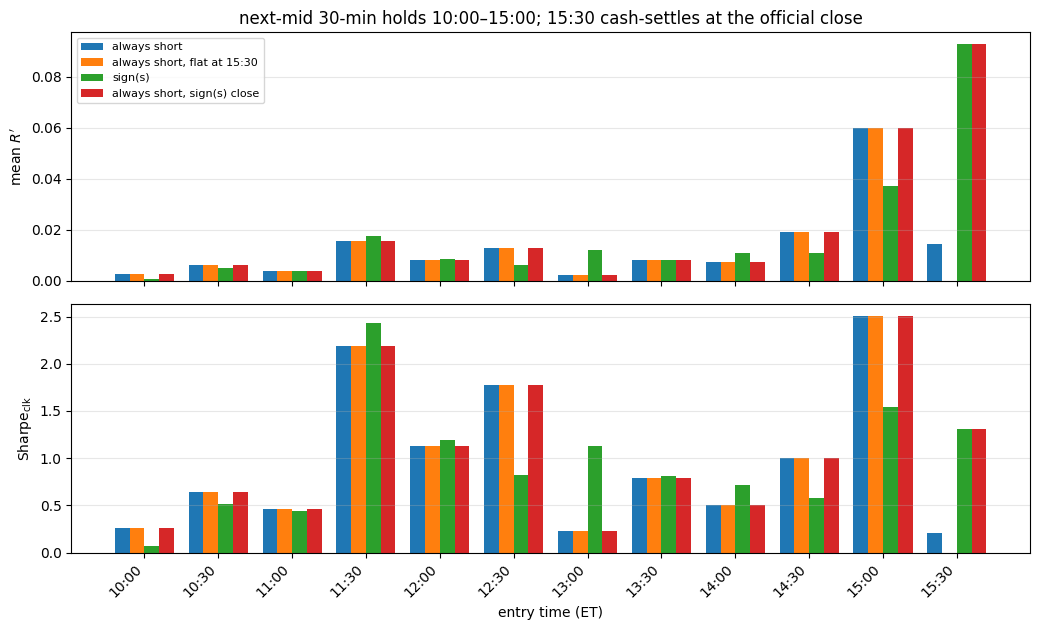

saved CSVs in C:\Users\james\CC Allowed\harxhar-0dte-professor\results\atm_straddle_intraday


In [13]:
clock_rows = []
for hhmm, g in work.groupby("hhmm", sort=True):
    for name, size in q.items():
        rp = (size * work["R"]).loc[g.index]
        st = asl.rule_row(rp, size.loc[g.index])
        clock_rows.append({"hhmm": hhmm, "rule": name, **st.to_dict()})
stab = pd.DataFrame(clock_rows)
stab.to_csv(OUT / "rule_by_entry_hhmm.csv", index=False)
print("Sharpe_clk = mean/std of this clock's R' * sqrt(252); one hold per expiration day")
print("Sharpe_ann is reserved for the daily sum of all twelve clocks (section 6)")
_clk = stab.rename(columns={"Sharpe_ann": "Sharpe_clk"})
print("always short by clock time")
print(_clk[_clk["rule"] == "always short"][
    ["hhmm", "n", "mean", "t_mean", "Sharpe_clk"]
].to_string(index=False))
print("sign(s) by clock time (window-matched signal)")
print(_clk[_clk["rule"] == "sign(s)"][
    ["hhmm", "n", "mean", "t_mean", "Sharpe_clk", "pct_buy"]
].to_string(index=False))

hour_rows = []
for hr, g in work.groupby("hour"):
    for name, size in q.items():
        rp = (size * work["R"]).loc[g.index]
        st = asl.rule_row(rp, size.loc[g.index])
        hour_rows.append({"hour": int(hr), "rule": name, **st.to_dict()})
htab = pd.DataFrame(hour_rows)
htab.to_csv(OUT / "rule_by_entry_hour.csv", index=False)

_rules = ["always short", "always short, flat at 15:30", "sign(s)", "always short, sign(s) close"]
_hh = list(stab["hhmm"].drop_duplicates())
_x = np.arange(len(_hh))
_w = 0.2
fig, axes = plt.subplots(2, 1, figsize=(10.5, 6.4), sharex=True)
for i, rule in enumerate(_rules):
    sub = stab[stab["rule"] == rule].set_index("hhmm").reindex(_hh)
    axes[0].bar(_x + (i - 1.5) * _w, sub["mean"].to_numpy(float), _w, label=rule)
    axes[1].bar(_x + (i - 1.5) * _w, sub["Sharpe_ann"].to_numpy(float), _w, label=rule)
for ax, ylab in ((axes[0], "mean $R'$"), (axes[1], r"Sharpe$_{\mathrm{clk}}$")):
    ax.axhline(0, color="k", lw=0.6)
    ax.set_ylabel(ylab)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_title("next-mid 30-min holds 10:00–15:00; 15:30 cash-settles at the official close")
axes[1].set_xticks(_x)
axes[1].set_xticklabels(_hh, rotation=45, ha="right")
axes[1].set_xlabel("entry time (ET)")
axes[0].legend(fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(OUT / "mean_by_entry_hhmm_as.png", dpi=120, bbox_inches="tight")
display(fig)
plt.close(fig)
print("saved CSVs in", OUT)


## 8c. Forecast QLIKE on this sample (2020--2024)

The book uses the block-diagonal ridge's $\widehat{RV}$ against next-bar
realized variance. QLIKE is $y/f-\log(y/f)-1$ (Patton; lower is better).
The cell scores it on the scored bars only, clock by clock, against two
$F_t$ comparators: the lagged expanding per-clock mean of $RV$ (the same
history that builds $w$), and the implied slice $w_t\mathrm{IV}^{2}_{\mathrm{hr}}h_t$.
A forecast that is fine on QLIKE and still loses on $\mathrm{sign}(s)$ is
not why the daytime Sharpes are small; the slice is.

In [14]:
def _qlike_mean(y, f):
    y = np.asarray(y, float)
    f = np.asarray(f, float)
    m = np.isfinite(y) & np.isfinite(f) & (y > 0) & (f > 0)
    if int(m.sum()) < 2:
        return float("nan"), 0
    r = y[m] / f[m]
    return float(np.mean(r - np.log(r) - 1.0)), int(m.sum())


# lagged per-clock mean of RV, same panel history as w (already in `prof`)
_naive = prof[clocks].expanding(min_periods=63).mean().shift(1)
_mi = pd.MultiIndex.from_arrays([work["date"], work["hhmm"]])
work = work.copy()
work["rv_naive"] = _naive.stack().reindex(_mi).to_numpy()
work["slice"] = work["iv_next30_matched"]

_ql_rows = []
for _hh, _g in work.groupby("hhmm", sort=True):
    _y = _g["rv_raw"]
    for _name, _f in (("ridge", _g["rv_hat"]), ("naive clock mean", _g["rv_naive"]),
                      ("implied slice", _g["slice"])):
        _q, _n = _qlike_mean(_y, _f)
        _ok = np.isfinite(_y) & np.isfinite(_f) & (_y > 0) & (_f > 0)
        _corr = float(pd.Series(_y[_ok]).corr(_f[_ok])) if int(_ok.sum()) > 2 else float("nan")
        _ratio = float(_y[_ok].mean() / _f[_ok].mean()) if int(_ok.sum()) else float("nan")
        _ql_rows.append({"hhmm": _hh, "forecast": _name, "n": _n, "QLIKE": _q,
                         "corr": _corr, "mean RV / mean f": _ratio})
_ql = pd.DataFrame(_ql_rows)
print("QLIKE on scored 2020-2024 bars (block-diagonal ridge vs two F_t comparators)")
print(_ql.pivot(index="hhmm", columns="forecast", values="QLIKE").to_string(float_format=lambda x: f"{x:.4f}"))
print("corr(RV, f)")
print(_ql.pivot(index="hhmm", columns="forecast", values="corr").to_string(float_format=lambda x: f"{x:.3f}"))
print("mean RV / mean f (1 = calibrated)")
print(_ql.pivot(index="hhmm", columns="forecast", values="mean RV / mean f").to_string(float_format=lambda x: f"{x:.3f}"))
for _name in ("ridge", "naive clock mean", "implied slice"):
    _sub = work
    _q, _n = _qlike_mean(_sub["rv_raw"], _sub[{"ridge": "rv_hat", "naive clock mean": "rv_naive",
                                               "implied slice": "slice"}[_name]])
    print(f"pooled {_name:18s} QLIKE {_q:.4f}  n={_n}")
_ql.to_csv(OUT / "forecast_qlike_by_clock_blk2.csv", index=False)

_day = work["hhmm"] != "15:30"
_close = work["hhmm"] == "15:30"
print("ridge QLIKE 10:00-15:00", _qlike_mean(work.loc[_day, "rv_raw"], work.loc[_day, "rv_hat"])[0])
print("ridge QLIKE 15:30      ", _qlike_mean(work.loc[_close, "rv_raw"], work.loc[_close, "rv_hat"])[0])
print("naive QLIKE 10:00-15:00", _qlike_mean(work.loc[_day, "rv_raw"], work.loc[_day, "rv_naive"])[0])
print("naive QLIKE 15:30      ", _qlike_mean(work.loc[_close, "rv_raw"], work.loc[_close, "rv_naive"])[0])


QLIKE on scored 2020-2024 bars (block-diagonal ridge vs two F_t comparators)
forecast  implied slice  naive clock mean  ridge
hhmm                                            
10:00            0.1557            0.6410 0.1800
10:30            0.1725            0.6472 0.1360
11:00            0.1797            0.7011 0.1490
11:30            0.1729            0.7520 0.1303
12:00            0.1906            0.7560 0.1339
12:30            0.1922            0.7809 0.1679
13:00            0.2237            0.7368 0.1786
13:30            0.2225            0.8682 0.2119
14:00            0.2015            0.9109 0.5396
14:30            0.2021            0.9995 0.2237
15:00            0.1521            0.8113 0.1554
15:30            0.1040            0.9011 0.1092
corr(RV, f)


forecast  implied slice  naive clock mean  ridge
hhmm                                            
10:00             0.895            -0.066  0.844
10:30             0.883            -0.121  0.779
11:00             0.773            -0.154  0.806
11:30             0.917            -0.148  0.810
12:00             0.859            -0.139  0.909
12:30             0.900            -0.111  0.955
13:00             0.828            -0.074  0.777
13:30             0.846             0.002  0.767
14:00             0.848             0.012  0.718
14:30             0.812            -0.024  0.724
15:00             0.880             0.067  0.829
15:30             0.936            -0.170  0.844
mean RV / mean f (1 = calibrated)
forecast  implied slice  naive clock mean  ridge
hhmm                                            
10:00             0.785             1.036  0.885
10:30             0.763             1.021  1.027
11:00             0.831             1.103  0.976
11:30             0.841            

## 8b. Hit rate, win size and the base rates, clock by clock

A **hit** is a bar the position makes money: $R_t>0$ on a bar the
matched signal buys ($s^{\mathrm{m}}_t>0$), $R_t<0$ on a bar it sells
($s^{\mathrm{m}}_t\le 0$). The **average win** and the **average
loss** are the means of the position's own return — $R_t$ on a buy
bar, $-R_t$ on a sell bar — over the bars where that return is
positive and over the bars where it is not, and the **mean per active
bar** is its mean over all of them. The **base rates** are those same
statistics over *every* bar at that clock, for the package held long
every day and for it held short every day, with no forecast used at
all.

The figure reads at every clock the way the deck's reads at 15:30:
the hit rates sit on the base rates (the buy side is $-0.001$ to
$+0.026$ of its base rate, the sell side $+0.001$ to $+0.053$), while
the average win on the bars the signal buys runs $1.01$–$1.20$ times
the base-rate win and the average loss on the bars it sells $0.72$–
$0.99$ of the base-rate loss — the signal is picking bigger wins, not
more of them — and the mean per active bar clears its base rate by a
few thousandths at every clock before 15:30 and by $+0.114$ long and
$+0.075$ short on the settlement bar.

matched sign(s) on the block-diagonal ridge, by entry clock; the base-rate columns use no forecast at all
         n  buy share  hit buy  base hit long  hit sell  base hit short  win buy  base win long  loss buy  base loss long  win sell  base win short  loss sell  base loss short  mean buy  base mean long  mean sell  base mean short  half-spread % prem  round trip % prem
hhmm                                                                                                                                                                                                                                                                        
10:00  864     0.2535   0.3379         0.3194    0.6868          0.6806   0.1403         0.1519   -0.0769         -0.0749    0.0743          0.0749    -0.1561          -0.1519   -0.0035         -0.0025     0.0021           0.0025              1.5760             3.1521
10:30  865     0.2428   0.3190         0.2925    0.7160          0.7075   0.1496       

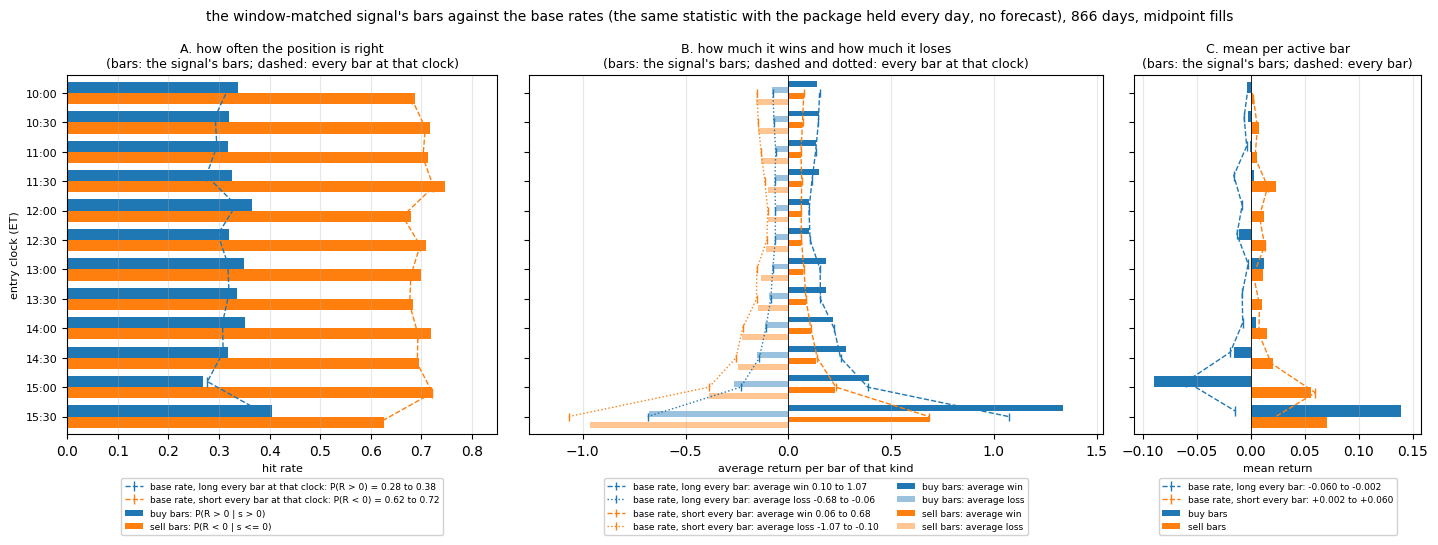

saved C:\Users\james\CC Allowed\harxhar-0dte-professor\results\atm_straddle_intraday\hitrate_by_entry_hhmm.png


In [15]:
# The deck's hit-rate reading at every entry clock. Every column is the position's
# OWN return u -- u = R on a buy bar, u = -R on a sell bar -- so a hit is u > 0 on
# both sides, the average win is the mean of u over the bars where it is positive
# and the average loss the mean over the bars where it is not. The base-rate
# columns are the same three statistics over every bar at that clock, long every
# day and short every day, with no forecast used at all. The last two columns are
# the median quoted half-spread at that clock in percent of midpoint premium and
# the round trip it implies: two crossings at every clock but 15:30, which
# cash-settles and so pays one.
def side_stats(u):
    u = np.asarray(u, float)
    win, loss = u[u > 0.0], u[u <= 0.0]
    return {
        "n": int(u.size),
        "hit rate": float((u > 0.0).mean()) if u.size else float("nan"),
        "avg win": float(win.mean()) if win.size else float("nan"),
        "avg loss": float(loss.mean()) if loss.size else float("nan"),
        "mean per active day": float(u.mean()) if u.size else float("nan"),
    }


_half_pct = 100.0 * (
    0.5 * ((work["ask_c"] + work["ask_p"]) - (work["bid_c"] + work["bid_p"])) / work["entry"]
)
_hr_rows = []
for _hhmm, _g in work.groupby("hhmm", sort=True):
    _r = _g["R"].astype(float).to_numpy()
    _isbuy = (_g["s_matched"] > 0).to_numpy(dtype=bool)
    _b, _s = side_stats(_r[_isbuy]), side_stats(-_r[~_isbuy])
    _bl, _bs = side_stats(_r), side_stats(-_r)
    _hs = float(_half_pct.loc[_g.index].median())
    _hr_rows.append({
        "hhmm": _hhmm, "n": int(len(_g)), "buy share": float(_isbuy.mean()),
        "hit buy": _b["hit rate"], "base hit long": _bl["hit rate"],
        "hit sell": _s["hit rate"], "base hit short": _bs["hit rate"],
        "win buy": _b["avg win"], "base win long": _bl["avg win"],
        "loss buy": _b["avg loss"], "base loss long": _bl["avg loss"],
        "win sell": _s["avg win"], "base win short": _bs["avg win"],
        "loss sell": _s["avg loss"], "base loss short": _bs["avg loss"],
        "mean buy": _b["mean per active day"], "base mean long": _bl["mean per active day"],
        "mean sell": _s["mean per active day"], "base mean short": _bs["mean per active day"],
        "half-spread % prem": _hs,
        "round trip % prem": _hs * (1.0 if _hhmm == "15:30" else 2.0),
    })
hrt = pd.DataFrame(_hr_rows).set_index("hhmm")
print("matched sign(s) on the block-diagonal ridge, by entry clock;",
      "the base-rate columns use no forecast at all")
print(hrt.to_string(float_format=lambda x: f"{x: .4f}"))
hrt.to_csv(OUT / "rule_by_entry_hhmm_hitrate.csv")
print("saved", OUT / "rule_by_entry_hhmm_hitrate.csv")

_ck = list(hrt.index)
_ys = np.arange(len(_ck))
fig, (axA, axB, axC) = plt.subplots(
    1, 3, figsize=(14.5, 5.6), sharey=True, gridspec_kw={"width_ratios": [3, 4, 2]})


def _rng(col, fmt="{:.2f}"):
    v = hrt[col].to_numpy(float)
    return fmt.format(np.nanmin(v)) + " to " + fmt.format(np.nanmax(v))


def _dress_clock(ax, title, xlab, ncol=1):
    # legends sit below the axes so they never cover a bar
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(xlab, fontsize=8)
    ax.legend(fontsize=6.5, loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=ncol, framealpha=0.9)
    ax.grid(axis="x", alpha=0.3)


def _pad_x(ax, vals):
    lo, hi = float(np.nanmin(vals)), float(np.nanmax(vals))
    pad = 0.08 * (hi - lo)
    ax.set_xlim(lo - pad, hi + pad)


axA.barh(_ys - 0.19, hrt["hit buy"], 0.38, color="C0", label="buy bars: P(R > 0 | s > 0)")
axA.barh(_ys + 0.19, hrt["hit sell"], 0.38, color="C1", label="sell bars: P(R < 0 | s <= 0)")
axA.plot(hrt["base hit long"], _ys - 0.19, ls="--", lw=1.0, color="C0", marker="|", ms=7,
         label="base rate, long every bar at that clock: P(R > 0) = " + _rng("base hit long"))
axA.plot(hrt["base hit short"], _ys + 0.19, ls="--", lw=1.0, color="C1", marker="|", ms=7,
         label="base rate, short every bar at that clock: P(R < 0) = " + _rng("base hit short"))
axA.set_yticks(_ys)
axA.set_yticklabels(_ck, fontsize=8)
axA.set_ylim(len(_ck) - 0.4, -0.6)
axA.set_xlim(0.0, 0.85)
axA.set_ylabel("entry clock (ET)", fontsize=8)
_dress_clock(axA, "A. how often the position is right\n(bars: the signal's bars; dashed: every bar at that clock)",
             "hit rate")

_SB = (("win buy", "C0", 1.0, "buy bars: average win"),
       ("loss buy", "C0", 0.45, "buy bars: average loss"),
       ("win sell", "C1", 1.0, "sell bars: average win"),
       ("loss sell", "C1", 0.45, "sell bars: average loss"))
for _k, (_col, _c, _a, _lab) in enumerate(_SB):
    axB.barh(_ys + (_k - 1.5) * 0.2, hrt[_col], 0.2, color=_c, alpha=_a, label=_lab)
for _col, _c, _ls, _who in (("base win long", "C0", "--", "long every bar: average win"),
                            ("base loss long", "C0", ":", "long every bar: average loss"),
                            ("base win short", "C1", "--", "short every bar: average win"),
                            ("base loss short", "C1", ":", "short every bar: average loss")):
    axB.plot(hrt[_col], _ys, ls=_ls, lw=1.0, color=_c, marker="|", ms=6,
             label="base rate, " + _who + " " + _rng(_col))
axB.axvline(0.0, color="k", lw=0.6)
_pad_x(axB, np.concatenate([hrt[c].to_numpy(float) for c, *_ in _SB]
                           + [hrt[c].to_numpy(float) for c in
                              ("base win long", "base loss long", "base win short", "base loss short")]))
_dress_clock(axB, "B. how much it wins and how much it loses\n(bars: the signal's bars; dashed and dotted: every bar at that clock)",
             "average return per bar of that kind", ncol=2)

axC.barh(_ys - 0.19, hrt["mean buy"], 0.38, color="C0", label="buy bars")
axC.barh(_ys + 0.19, hrt["mean sell"], 0.38, color="C1", label="sell bars")
axC.plot(hrt["base mean long"], _ys - 0.19, ls="--", lw=1.0, color="C0", marker="|", ms=7,
         label="base rate, long every bar: " + _rng("base mean long", "{:+.3f}"))
axC.plot(hrt["base mean short"], _ys + 0.19, ls="--", lw=1.0, color="C1", marker="|", ms=7,
         label="base rate, short every bar: " + _rng("base mean short", "{:+.3f}"))
axC.axvline(0.0, color="k", lw=0.6)
_pad_x(axC, np.concatenate([hrt[c].to_numpy(float) for c in
                            ("mean buy", "mean sell", "base mean long", "base mean short")] + [np.zeros(1)]))
_dress_clock(axC, "C. mean per active bar\n(bars: the signal's bars; dashed: every bar)",
             "mean return")

fig.suptitle("the window-matched signal's bars against the base rates (the same statistic with the package held every day, "
             f"no forecast), {int(work['date'].nunique())} days, midpoint fills", fontsize=10)
fig.tight_layout()
fig.savefig(OUT / "hitrate_by_entry_hhmm.png", dpi=120, bbox_inches="tight")
display(fig)
plt.close(fig)
print("saved", OUT / "hitrate_by_entry_hhmm.png")


## 9. Buy-signal fingerprint (day $\times$ clock)

Each column is one expiration day, each row one 30-min clock. The colour is the position the window-matched signal takes for that bar: blue buy ($s^{\mathrm{m}}_t>0$), red short ($s^{\mathrm{m}}_t\le 0$), grey flat (no implied quote: the solver's bracket node was censored). The §8 tables average this grid along each row.

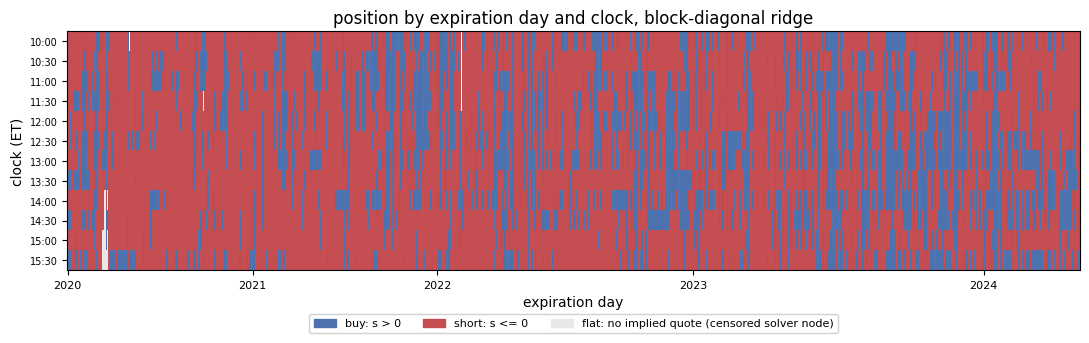

buy share by year (%)
date
2020    17.400000
2021    22.800000
2022    28.500000
2023    37.000000
2024    33.800000


mean same-stance run length within a day (bars): 4.93


In [16]:
grid = work.assign(qsign=pos_m.fillna(0.0)).pivot_table(
    index="hhmm", columns="date", values="qsign", aggfunc="first"
)
grid = grid.sort_index()

from matplotlib.colors import BoundaryNorm, ListedColormap
cmap = ListedColormap(["#c44e52", "#e8e8e8", "#4c72b0"])
norm = BoundaryNorm([-1.5, -0.5, 0.5, 1.5], cmap.N)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.imshow(grid.to_numpy(), aspect="auto", cmap=cmap, norm=norm, interpolation="none")
ax.set_yticks(range(len(grid.index)), grid.index, fontsize=7)
yrs = pd.DatetimeIndex(grid.columns).year
ticks = [int(np.argmax(yrs == y)) for y in sorted(set(yrs))]
ax.set_xticks(ticks, sorted(set(yrs)), fontsize=8)
ax.set_xlabel("expiration day")
ax.set_ylabel("clock (ET)")
ax.set_title("position by expiration day and clock, block-diagonal ridge")
from matplotlib.patches import Patch
ax.legend(
    handles=[Patch(color="#4c72b0", label="buy: s > 0"), Patch(color="#c44e52", label="short: s <= 0"),
             Patch(color="#e8e8e8", label="flat: no implied quote (censored solver node)")],
    fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, framealpha=0.9,
)
fig.tight_layout()
fig.savefig(OUT / "buy_fingerprint_day_clock.png", dpi=120, bbox_inches="tight")
display(fig)
plt.close(fig)

sgn = pos_m.fillna(0.0)
by_year = work.assign(buy=(sgn > 0)).groupby(work["date"].dt.year)["buy"].mean() * 100.0
print("buy share by year (%)")
print(by_year.round(1).to_string())
runs = (
    work.assign(qsign=sgn)
    .groupby("date")["qsign"]
    .apply(lambda s: (s != s.shift()).cumsum().value_counts().mean())
)
print("mean same-stance run length within a day (bars):", round(float(runs.mean()), 2))


## 10. The 30-minute implied is allocated, not quoted

The vendor IV at clock $t$ is a price for variance **from $t$ to the close**. This notebook holds 30 minutes, so §5b manufactures a 30-minute implied as $w_t$ times that remaining variance. $w_t$ is the expanding diurnal share of prior days; it is not a bid or an ask.

A quoted window would be a second expiration at the same stamp. 0DTE remaining variance and 1DTE remaining variance are two prices; the calendar (long one, short the other) is then a traded claim on their difference, not a $w$-slice of a single expiry. That calendar is still not a 30-minute option — listed SPX does not expire every half hour — but it would replace the homemade share with something the market posts.

This chain has only 0DTE: every row of `data/spxw_chain.parquet` is zero days to expiration, so there is no 1DTE quote at 10:00 and no calendar to price. Until a second expiry is on disk, the daytime comparison in §5b is forecast versus a constructed slice.